# Лабораторная работа №17: Diffusion model с нуля и classifier-free guidance

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать forward noising и noise prediction.
- Обучить compact conditional network.
- Добавить CFG и сравнить guidance scales.

## Теоретическая часть

DDPM постепенно добавляет Gaussian noise, затем обучает network обращать процесс. Classifier-free guidance смешивает conditional и unconditional predictions и управляет компромиссом fidelity/diversity.

![DDPM](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/diffusers/ddpm.png)


DDPM обучает εθ(x_t,t,y) восстанавливать внесённый шум. При classifier-free dropout условие заменяется специальным индексом 10; на inference ε_cfg=ε_u+w(ε_c−ε_u). Для MNIST качество класса проверяет отдельно обученный на train классификатор, его точность на test обязательно сообщается.

Прямой процесс: $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon$. CFG: $\hat\epsilon=\epsilon_u+w(\epsilon_c-\epsilon_u)$; при двух вызовах сети на шаг $\mathrm{NFE}=2T$.

## Теория

### 1. Диффузионные модели (DDPM)

DDPM (Denoising Diffusion Probabilistic Models) — это генеративные модели, которые создают изображения с помощью постепенного добавления шума и последующего восстановления исходных данных.

Работа модели состоит из двух процессов: прямого и обратного.

В прямом процессе к исходному изображению постепенно добавляется гауссовский шум. На каждом шаге количество шума увеличивается, пока изображение практически полностью не превращается в случайный шум.

Для описания процесса используются следующие коэффициенты:

$$
\alpha_t = 1-\beta_t
$$

где $\beta_t$ определяет количество шума, добавляемого на шаге $t$.

Также вводится накопленный коэффициент:

$$
\bar{\alpha}_t = \prod_{s=1}^{t}\alpha_s
$$

Он показывает, какая часть исходного сигнала сохраняется после нескольких шагов диффузии.

В DDPM не обязательно последовательно выполнять все шаги прямого процесса, чтобы получить зашумлённое изображение. Можно сразу вычислить результат для произвольного временного шага:

$$
x_t = \sqrt{\bar{\alpha}_t}x_0 +
\sqrt{1-\bar{\alpha}_t}\epsilon
$$

где:
- $x_0$ — исходное изображение;
- $x_t$ — зашумлённое изображение;
- $\epsilon$ — случайный гауссовский шум;
- $\bar{\alpha}_t$ — накопленный коэффициент сохранения сигнала.

В работе использовалось 1000 временных шагов и линейное расписание коэффициента шума от $10^{-4}$ до $0.02$.

### 2. Обучение модели предсказанию шума

Основная задача нейросети в DDPM — научиться определять шум, который был добавлен к исходному изображению.

Для этого используется модель-предсказатель шума:

$$
\epsilon_\theta(x_t,t)
$$

Она принимает зашумлённое изображение и номер временного шага, а возвращает оценку добавленного шума.

Обучение выполняется с помощью функции потерь MSE:

$$
L_{\text{simple}} =
\mathbb{E}_{x_0,t,\epsilon}
\left[
\left\|
\epsilon -
\epsilon_\theta(x_t,t)
\right\|^2
\right]
$$

Чем меньше значение этой функции, тем точнее модель предсказывает добавленный шум.

В данной работе использовалась компактная нейросеть TinyDenoiser. Для передачи информации о временном шаге применялось синусоидальное позиционное кодирование. Информация о классе цифры передавалась через embedding.

Внутри остаточных блоков использовалась FiLM-модуляция. Она позволяет учитывать временной шаг и класс при обработке изображения, изменяя масштаб и смещение промежуточных признаков:

$$
h' = h \cdot (1+\gamma) + \beta
$$

где $h$ — признаки изображения, а $\gamma$ и $\beta$ — параметры, полученные из условного представления.

### 3. Условная генерация и Classifier-Free Guidance

Обычная DDPM может генерировать изображения без указания конкретного класса. Однако в данной работе необходимо управлять генерацией, чтобы модель создавала определённую цифру.

Для этого используется условная модель, которая получает не только изображение и временной шаг, но и метку класса:

$$
\epsilon_\theta(x_t,t,y)
$$

где $y$ — номер цифры от 0 до 9.

Для реализации Classifier-Free Guidance (CFG) модель обучается одновременно в условном и безусловном режимах. Во время обучения с некоторой вероятностью метка класса заменяется специальной null-меткой. В данной работе для этого использовался класс с индексом 10.

При генерации выполняются два предсказания:
- безусловное — без информации о классе;
- условное — с заданной меткой цифры.

Затем они объединяются по формуле:

$$
\epsilon_{\text{CFG}} =
\epsilon_{\text{uncond}} +
w(\epsilon_{\text{cond}}-\epsilon_{\text{uncond}})
$$

Здесь $w$ — сила guidance.

При $w=0$ используется только безусловное предсказание. При $w=1$ получается обычное условное предсказание. При увеличении $w$ усиливается влияние заданного класса.

Слишком большое значение guidance может привести к ухудшению разнообразия или появлению искажений, поэтому важно подбирать этот параметр экспериментально.

В работе сравнивались значения $w=0$, $w=1$, $w=3$ и $w=5$.

### 4. Обратный процесс диффузии

После обучения модель можно использовать для генерации изображений. Для этого сначала создаётся случайный шум:

$$
x_T \sim \mathcal{N}(0,I)
$$

Затем выполняется обратный процесс: модель последовательно предсказывает шум и постепенно восстанавливает изображение.

Среднее обратного распределения DDPM вычисляется следующим образом:

$$
\mu_\theta(x_t,t) =
\frac{1}{\sqrt{\alpha_t}}
\left(
x_t -
\frac{\beta_t}{\sqrt{1-\bar{\alpha}_t}}
\epsilon_\theta(x_t,t)
\right)
$$

На каждом шаге к полученному значению добавляется случайная составляющая, соответствующая дисперсии обратного перехода:

$$
x_{t-1} =
\mu_\theta(x_t,t) + \sigma_t z
$$

где $z$ — случайный гауссовский шум, а $\sigma_t$ определяется расписанием диффузии. На последнем шаге генерации дополнительный шум не добавляется.

В результате после прохождения всех временных шагов получается изображение цифры.

При использовании CFG на каждом шаге необходимо выполнить два предсказания шума: условное и безусловное. Поэтому количество вычислений нейросети (NFE) при 1000 шагах составляет:

$$
NFE = 2 \cdot 1000 = 2000
$$

### 5. Оценка качества генерации

Для оценки результатов генерации в работе использовался отдельный классификатор DigitClassifier. Он обучался на реальных изображениях MNIST и не участвовал в обучении DDPM.

После генерации классификатор определял цифру на каждом изображении. Полученная метка сравнивалась с той, которая была задана модели при генерации.

Точность вычислялась по формуле:

$$
Accuracy =
\frac{N_{\text{correct}}}{N_{\text{total}}}
\cdot 100\%
$$

Дополнительно рассчитывалась точность отдельно для каждого класса. Это позволяет увидеть, какие цифры модель генерирует лучше, а какие хуже.

Также оценивалась ошибка предсказания шума MSE на разных временных шагах. Она рассчитывалась отдельно для условного и безусловного режимов:

$$
MSE =
\frac{1}{N}
\sum_{i=1}^{N}
(\epsilon_i-\hat{\epsilon}_i)^2
$$

Такое сравнение позволяет проверить, насколько сильно информация о классе влияет на предсказание шума.

### 6. Абляционное исследование CFG dropout

Дополнительно исследовалось влияние вероятности CFG dropout на обучение модели.

CFG dropout определяет вероятность того, что метка класса будет заменена на null-класс. При большем значении dropout модель чаще обучается без информации о целевой цифре.

В эксперименте сравнивались два значения:

- 10% — базовая конфигурация;
- 20% — изменённая конфигурация.

При этом остальные параметры, включая архитектуру, seed, обучающие данные и количество шагов обучения, оставались одинаковыми.

Для сравнения использовалась относительная разница ошибок:

$$
\Delta MSE =
\frac{MSE_{20\%}-MSE_{10\%}}
{MSE_{10\%}}
\cdot 100\%
$$

Отрицательное значение означает, что ошибка при dropout 20% стала меньше, а положительное — что она увеличилась.

Цель этого эксперимента — проверить, как частота обучения безусловного режима влияет на способность модели предсказывать шум как с использованием метки класса, так и без неё.

### Экспериментальный протокол

Данные MNIST: train первые 20 000, test первые 2 000, без пересечения. Полное обучение: 10 000 шагов; smoke: 2. Основной результат — реальные MNIST checkpoint и условная генерация при разных w. Для продолжения после сбоя сохраняйте artifacts в Drive или задайте CV_ARTIFACTS. Не смешивайте smoke/full checkpoint.

### Материалы

- [DDPM paper](https://arxiv.org/abs/2006.11239)
- [Annotated Diffusion](https://huggingface.co/blog/annotated-diffusion)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
PROJECT_DIR = Path('/content/drive/MyDrive/lab17')
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 14
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', PROJECT_DIR / 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', PROJECT_DIR / 'data'))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2))
print({'device':DEVICE,'fast_dev_run':FAST_DEV_RUN,'artifacts':str(ARTIFACTS)})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': '/content/drive/MyDrive/lab17/artifacts'}


In [3]:
# Библиотеки

import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import copy
import pandas as pd

### Расписание прямой диффузии

*Вес: 1 балл.*

**Постановка.** Шумовой schedule и форма выхода denoiser определяют корректность всех последующих шагов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Задайте beta, alpha и alpha-bar, проверьте формулу внесения внешнего шума.

**Результат.** Проверяемое состояние «Расписание прямой диффузии» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Задайте beta, alpha и alpha-bar, проверьте формулу внесения внешнего шума» и его результат доступен следующему этапу.

In [4]:
# ============================================================
# РАСПИСАНИЕ ПРЯМОЙ ДИФФУЗИИ
# ============================================================

# Количество шагов диффузии
T = 1000

# ------------------------------------------------------------
# 1. Создание расписания beta, alpha и alpha_bar
# ------------------------------------------------------------

def diffusion_schedule(num_steps=1000, beta_start=1e-4, beta_end=0.02, device=DEVICE):
    """
    Создает расписание параметров прямого процесса DDPM.

    beta      - интенсивность добавления шума;
    alpha     - доля сохраняемой информации на одном шаге;
    alpha_bar - накопленная доля исходного изображения.
    """

    beta = torch.linspace(
        beta_start,
        beta_end,
        num_steps,
        device=device,
        dtype=torch.float32
    )

    alpha = 1.0 - beta

    alpha_bar = torch.cumprod(alpha, dim=0)

    return {
        'beta': beta,
        'alpha': alpha,
        'alpha_bar': alpha_bar
    }


# Создаем расписание
SCHEDULE = diffusion_schedule(T)

# Сохраняем основные массивы в глобальных переменных.
# Они будут использоваться в следующих заданиях.

BETA = SCHEDULE['beta']
ALPHA = SCHEDULE['alpha']
ALPHA_BAR = SCHEDULE['alpha_bar']


# ------------------------------------------------------------
# 2. Функция добавления шума q_sample
# ------------------------------------------------------------

def q_sample(x0, t, noise=None, schedule=None):
    """
    Добавляет Gaussian noise к исходным изображениям.

    x0    - исходные изображения [B, C, H, W];
    t     - номера шагов диффузии [B];
    noise - случайный шум той же формы, что x0.

    Возвращает:
    xt - зашумленные изображения.
    """

    if schedule is None:
        schedule = SCHEDULE

    if noise is None:
        noise = torch.randn_like(x0)

    alpha_bar = schedule['alpha_bar']

    # Получаем alpha_bar для каждого элемента batch.
    alpha_bar_t = alpha_bar[t.long()]

    # Приводим размерность к [B, 1, 1, 1],
    # чтобы корректно умножать на изображения.
    alpha_bar_t = alpha_bar_t.view(-1, 1, 1, 1)

    # Формула прямой диффузии:
    # xt = sqrt(alpha_bar_t) * x0
    #    + sqrt(1 - alpha_bar_t) * noise

    xt = (
        torch.sqrt(alpha_bar_t) * x0
        +
        torch.sqrt(1.0 - alpha_bar_t) * noise
    )

    return xt


# ------------------------------------------------------------
# 3. Проверка расписания
# ------------------------------------------------------------

assert BETA.shape == (T,)
assert ALPHA.shape == (T,)
assert ALPHA_BAR.shape == (T,)

assert torch.all(BETA > 0)
assert torch.all(BETA < 1)
assert torch.all(ALPHA > 0)
assert torch.all(ALPHA_BAR > 0)

assert torch.all(ALPHA_BAR[1:] <= ALPHA_BAR[:-1])


# ------------------------------------------------------------
# 4. Проверка формулы добавления шума
# ------------------------------------------------------------

# В FAST_DEV_RUN проверяем на небольшом batch.
# В полном режиме используем более крупный batch.

test_batch_size = 2 if FAST_DEV_RUN else 16

x0_test = torch.randn(
    test_batch_size, 1, 28, 28,
    device=DEVICE
)

# Для проверки используем разные шаги диффузии.
t_test = torch.linspace(
    0,
    T - 1,
    test_batch_size,
    device=DEVICE
).long()

# Генерируем известный нам шум.
noise_test = torch.randn_like(x0_test)

# Получаем зашумленное изображение.
xt_test = q_sample(
    x0_test,
    t_test,
    noise_test
)

# Независимо вычисляем результат по исходной формуле.
alpha_bar_test = ALPHA_BAR[t_test].view(-1, 1, 1, 1)

xt_expected = (
    torch.sqrt(alpha_bar_test) * x0_test
    +
    torch.sqrt(1.0 - alpha_bar_test) * noise_test
)

# Проверяем совпадение результатов.
max_formula_error = (
    xt_test - xt_expected
).abs().max().item()

assert xt_test.shape == x0_test.shape
assert torch.isfinite(xt_test).all()
assert max_formula_error < 1e-6


# ------------------------------------------------------------
# 5. Сохранение артефактов
# ------------------------------------------------------------

# Сохраняем расписание.
np.savez_compressed(
    ARTIFACTS / 'diffusion_schedule.npz',
    beta=BETA.cpu().numpy(),
    alpha=ALPHA.cpu().numpy(),
    alpha_bar=ALPHA_BAR.cpu().numpy()
)

# Собираем измеренные значения.
schedule_metrics = {
    'status': 'completed',
    'task': 'Расписание прямой диффузии',
    'fast_dev_run': FAST_DEV_RUN,
    'device': DEVICE,
    'T': T,
    'beta_min': BETA.min().item(),
    'beta_max': BETA.max().item(),
    'alpha_min': ALPHA.min().item(),
    'alpha_max': ALPHA.max().item(),
    'alpha_bar_first': ALPHA_BAR[0].item(),
    'alpha_bar_last': ALPHA_BAR[-1].item(),
    'test_batch_size': test_batch_size,
    'input_shape': list(x0_test.shape),
    'output_shape': list(xt_test.shape),
    'max_formula_error': max_formula_error
}

save_json(
    'task17_1_diffusion_schedule.json',
    schedule_metrics
)

# ------------------------------------------------------------
# 6. Вывод результатов
# ------------------------------------------------------------

for key, value in schedule_metrics.items():
    print(f'{key}: {value}')

print('\nСозданные артефакты:')
print(ARTIFACTS / 'diffusion_schedule.npz')
print(ARTIFACTS / 'task17_1_diffusion_schedule.json')


status: completed
task: Расписание прямой диффузии
fast_dev_run: False
device: cuda
T: 1000
beta_min: 9.999999747378752e-05
beta_max: 0.019999999552965164
alpha_min: 0.9800000190734863
alpha_max: 0.9998999834060669
alpha_bar_first: 0.9998999834060669
alpha_bar_last: 4.035829260828905e-05
test_batch_size: 16
input_shape: [16, 1, 28, 28]
output_shape: [16, 1, 28, 28]
max_formula_error: 0.0

Созданные артефакты:
/content/drive/MyDrive/lab17/artifacts/diffusion_schedule.npz
/content/drive/MyDrive/lab17/artifacts/task17_1_diffusion_schedule.json


### Условный denoiser и проверка форм

*Вес: 1 балл.*

**Постановка.** Шумовой schedule и форма выхода denoiser определяют корректность всех последующих шагов. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте сеть с пространственными блоками и embeddings времени/класса; проверьте форму выхода.

**Результат.** Проверяемое состояние «Условный denoiser и проверка форм» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте сеть с пространственными блоками и embeddings времени/класса; проверьте форму выхода» и его результат доступен следующему этапу.

In [5]:
# ------------------------------------------------------------
# 1. Time embedding
# ------------------------------------------------------------

class SinusoidalTimeEmbedding(nn.Module):
    """
    Преобразует timestep в синусоидальный embedding.
    """
    def __init__(self, embedding_dim):
        super().__init__()

        self.embedding_dim = embedding_dim

    def forward(self, t):

        half_dim = self.embedding_dim // 2

        frequencies = torch.exp(
            -np.log(10000.0)
            * torch.arange(
                half_dim,
                device=t.device,
                dtype=torch.float32
            )
            / max(half_dim - 1, 1)
        )

        angles = t.float().unsqueeze(1) * frequencies.unsqueeze(0)

        embedding = torch.cat(
            [torch.sin(angles), torch.cos(angles)],
            dim=1
        )

        return embedding


# ------------------------------------------------------------
# 2. Residual convolution block с conditioning
# ------------------------------------------------------------

class ConditionedResBlock(nn.Module):
    """
    Пространственный residual block.

    Использует time/class conditioning через FiLM:
    scale и shift.
    """
    def __init__(self, channels, condition_dim):
        super().__init__()

        self.norm1 = nn.GroupNorm(8, channels)
        self.conv1 = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1
        )

        self.norm2 = nn.GroupNorm(8, channels)

        self.condition_projection = nn.Linear(
            condition_dim,
            channels * 2
        )

        self.conv2 = nn.Conv2d(
            channels,
            channels,
            kernel_size=3,
            padding=1
        )

    def forward(self, x, condition):

        residual = x

        # Первая свертка
        h = self.norm1(x)
        h = F.silu(h)
        h = self.conv1(h)

        # Вторая нормализация
        h = self.norm2(h)

        # Получаем scale и shift из embeddings
        scale, shift = self.condition_projection(
            condition
        ).chunk(2, dim=1)

        # Приводим к размерности [B, C, 1, 1]
        scale = scale[:, :, None, None]
        shift = shift[:, :, None, None]

        # Conditioning через FiLM
        h = h * (1.0 + scale) + shift

        h = F.silu(h)
        h = self.conv2(h)

        # Residual connection
        return h + residual

# ------------------------------------------------------------
# 3. Основная сеть TinyDenoiser
# ------------------------------------------------------------

class TinyDenoiser(nn.Module):
    """
    Условная нейросеть для предсказания шума DDPM.
    Вход:
        x_t: [B, 1, 28, 28]
        t:   [B]
        y:   [B], классы 0-9 или null class 10

    Выход:
        predicted_noise: [B, 1, 28, 28]
    """
    def __init__(
        self,
        image_channels=1,
        num_classes=10,
        channels=64,
        embedding_dim=128
    ):
        super().__init__()

        self.num_classes = num_classes
        self.null_class = num_classes

        # ----------------------------------------------------
        # Embeddings времени
        # ----------------------------------------------------

        self.time_embedding = nn.Sequential(
            SinusoidalTimeEmbedding(embedding_dim),
            nn.Linear(embedding_dim, embedding_dim),
            nn.SiLU(),
            nn.Linear(embedding_dim, embedding_dim)
        )

        # ----------------------------------------------------
        # Embeddings классов
        # Дополнительный класс 10 означает отсутствие условия.
        # ----------------------------------------------------

        self.class_embedding = nn.Embedding(
            num_classes + 1,
            embedding_dim
        )

        # ----------------------------------------------------
        # Начальная свертка
        # ----------------------------------------------------

        self.input_conv = nn.Conv2d(
            image_channels,
            channels,
            kernel_size=3,
            padding=1
        )

        # ----------------------------------------------------
        # Пространственные residual blocks
        # ----------------------------------------------------

        self.res_block1 = ConditionedResBlock(
            channels,
            embedding_dim
        )

        self.res_block2 = ConditionedResBlock(
            channels,
            embedding_dim
        )

        self.res_block3 = ConditionedResBlock(
            channels,
            embedding_dim
        )

        # ----------------------------------------------------
        # Выходной слой
        # ----------------------------------------------------

        self.output_norm = nn.GroupNorm(8, channels)

        self.output_conv = nn.Conv2d(
            channels,
            image_channels,
            kernel_size=3,
            padding=1
        )

    def forward(self, x_t, t, y):

        # Временной embedding
        time_emb = self.time_embedding(t)

        # Классовый embedding
        class_emb = self.class_embedding(y.long())

        # Объединяем информацию о времени и классе
        condition = time_emb + class_emb

        # Обрабатываем изображение
        h = self.input_conv(x_t)

        h = self.res_block1(h, condition)
        h = self.res_block2(h, condition)
        h = self.res_block3(h, condition)

        h = self.output_norm(h)
        h = F.silu(h)

        predicted_noise = self.output_conv(h)

        return predicted_noise


# ------------------------------------------------------------
# 4. Создание модели
# ------------------------------------------------------------

model = TinyDenoiser().to(DEVICE)


# ------------------------------------------------------------
# 5. Проверка формы выхода
# ------------------------------------------------------------

test_batch_size = 2 if FAST_DEV_RUN else 16

x_test = torch.randn(
    test_batch_size,
    1,
    28,
    28,
    device=DEVICE
)

t_test = torch.randint(
    low=0,
    high=T,
    size=(test_batch_size,),
    device=DEVICE
)

# Проверяем обычные классы.
y_test = torch.randint(
    low=0,
    high=10,
    size=(test_batch_size,),
    device=DEVICE
)

# Дополнительно проверяем unconditional режим.
y_unconditional = torch.full(
    (test_batch_size,),
    10,
    device=DEVICE,
    dtype=torch.long
)

model.eval()

with torch.no_grad():

    predicted_noise = model(
        x_test,
        t_test,
        y_test
    )

    predicted_noise_unconditional = model(
        x_test,
        t_test,
        y_unconditional
    )


# ------------------------------------------------------------
# 6. Проверка корректности
# ------------------------------------------------------------

assert predicted_noise.shape == x_test.shape

assert predicted_noise_unconditional.shape == x_test.shape

assert torch.isfinite(predicted_noise).all()

assert torch.isfinite(predicted_noise_unconditional).all()

# Число обучаемых параметров
num_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


# ------------------------------------------------------------
# 7. Сохранение артефактов
# ------------------------------------------------------------

model_config = {
    'image_channels': 1,
    'num_classes': 10,
    'channels': 64,
    'embedding_dim': 128,
    'null_class': 10
}

# Это начальный checkpoint, а не обученная diffusion model.
torch.save(
    {
        'model_state_dict': model.state_dict(),
        'model_config': model_config,
        'trained': False,
        'fast_dev_run': FAST_DEV_RUN
    },
    ARTIFACTS / 'tiny_denoiser_init.pt'
)

denoiser_metrics = {
    'status': 'completed',
    'task': 'Условный denoiser и проверка форм',
    'fast_dev_run': FAST_DEV_RUN,
    'device': DEVICE,
    'input_shape': list(x_test.shape),
    'conditional_output_shape': list(predicted_noise.shape),
    'unconditional_output_shape': list(
        predicted_noise_unconditional.shape
    ),
    'num_parameters': num_parameters,
    'num_classes': 10,
    'null_class': 10,
    'all_outputs_finite': True
}

save_json(
    'task17_2_denoiser_metrics.json',
    denoiser_metrics
)


# ------------------------------------------------------------
# 8. Вывод результатов
# ------------------------------------------------------------
for key, value in denoiser_metrics.items():
    print(f'{key}: {value}')

print('\nСозданные артефакты:')
print(ARTIFACTS / 'tiny_denoiser_init.pt')
print(ARTIFACTS / 'task17_2_denoiser_metrics.json')

status: completed
task: Условный denoiser и проверка форм
fast_dev_run: False
device: cuda
input_shape: [16, 1, 28, 28]
conditional_output_shape: [16, 1, 28, 28]
unconditional_output_shape: [16, 1, 28, 28]
num_parameters: 307649
num_classes: 10
null_class: 10
all_outputs_finite: True

Созданные артефакты:
/content/drive/MyDrive/lab17/artifacts/tiny_denoiser_init.pt
/content/drive/MyDrive/lab17/artifacts/task17_2_denoiser_metrics.json


### Train/test MNIST для DDPM

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите фиксированный непересекающийся split и DataLoader.

**Результат.** Проверяемое состояние «Train/test MNIST для DDPM» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите фиксированный непересекающийся split и DataLoader» и его результат доступен следующему этапу.

In [6]:
# ============================================================
# TRAIN/TEST MNIST ДЛЯ DDPM
# ============================================================

# ------------------------------------------------------------
# 1. Параметры загрузки данных
# ------------------------------------------------------------

TRAIN_SIZE = 20_000
TEST_SIZE = 2_000

BATCH_SIZE = 32 if FAST_DEV_RUN else 128

NUM_WORKERS = 2

# Фиксируем генератор DataLoader для воспроизводимости.
loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)


# ------------------------------------------------------------
# 2. Преобразование изображений
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.ToTensor(),

    # Переводим значения пикселей из [0, 1] в [-1, 1].
    transforms.Normalize((0.5,), (0.5,))
])


# ------------------------------------------------------------
# 3. Загрузка MNIST
# ------------------------------------------------------------

mnist_train_full = datasets.MNIST(
    root=str(DATA_ROOT),
    train=True,
    download=True,
    transform=transform
)

mnist_test_full = datasets.MNIST(
    root=str(DATA_ROOT),
    train=False,
    download=True,
    transform=transform
)


# ------------------------------------------------------------
# 4. Формирование фиксированных выборок
# ------------------------------------------------------------

# Берем первые 20 000 изображений официального train.
train_indices = list(range(TRAIN_SIZE))

# Берем первые 2 000 изображений официального test.
test_indices = list(range(TEST_SIZE))

train_dataset = Subset(
    mnist_train_full,
    train_indices
)

test_dataset = Subset(
    mnist_test_full,
    test_indices
)


# ------------------------------------------------------------
# 5. Создание DataLoader
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE == 'cuda'),
    drop_last=True,
    generator=loader_generator
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE == 'cuda')
)


# ------------------------------------------------------------
# 6. Проверка данных
# ------------------------------------------------------------

x_batch, y_batch = next(iter(train_loader))
x_test_batch, y_test_batch = next(iter(test_loader))

assert len(train_dataset) == TRAIN_SIZE
assert len(test_dataset) == TEST_SIZE

assert x_batch.shape == (BATCH_SIZE, 1, 28, 28)
assert y_batch.shape == (BATCH_SIZE,)

assert x_test_batch.shape[1:] == (1, 28, 28)

assert x_batch.min() >= -1.0
assert x_batch.max() <= 1.0

assert y_batch.min() >= 0
assert y_batch.max() <= 9


# Проверяем непересечение официальных выборок.
# У train и test разные исходные наборы данных MNIST.

assert mnist_train_full.train is True
assert mnist_test_full.train is False


# ------------------------------------------------------------
# 7. Статистика классов
# ------------------------------------------------------------

train_labels = mnist_train_full.targets[train_indices].numpy()
test_labels = mnist_test_full.targets[test_indices].numpy()

train_class_counts = np.bincount(
    train_labels,
    minlength=10
)

test_class_counts = np.bincount(
    test_labels,
    minlength=10
)


# ------------------------------------------------------------
# 8. Сохранение split
# ------------------------------------------------------------

np.savez_compressed(
    ARTIFACTS / 'mnist_split.npz',
    train_indices=np.array(train_indices),
    test_indices=np.array(test_indices),
    train_labels=train_labels,
    test_labels=test_labels
)

mnist_metrics = {
    'status': 'completed',
    'task': 'Train/test MNIST для DDPM',
    'fast_dev_run': FAST_DEV_RUN,
    'device': DEVICE,

    'train_size': len(train_dataset),
    'test_size': len(test_dataset),

    'batch_size': BATCH_SIZE,
    'train_batches': len(train_loader),
    'test_batches': len(test_loader),

    'image_shape': list(x_batch.shape[1:]),
    'pixel_min': x_batch.min().item(),
    'pixel_max': x_batch.max().item(),

    'train_class_counts': train_class_counts.tolist(),
    'test_class_counts': test_class_counts.tolist(),

    'train_source': 'MNIST official train, first 20000',
    'test_source': 'MNIST official test, first 2000',

    'normalization': 'ToTensor + Normalize(0.5, 0.5)',
    'seed': SEED
}

save_json(
    'task17_3_mnist_split.json',
    mnist_metrics
)


# ------------------------------------------------------------
# 9. Вывод результатов
# ------------------------------------------------------------

for key, value in mnist_metrics.items():
    print(f'{key}: {value}')

print('\nПервые batch:')
print('Train images:', x_batch.shape)
print('Train labels:', y_batch.shape)
print('Test images:', x_test_batch.shape)
print('Test labels:', y_test_batch.shape)

print('\nКоличество изображений по классам:')
for digit in range(10):
    print(
        f'Цифра {digit}: '
        f'train={train_class_counts[digit]}, '
        f'test={test_class_counts[digit]}'
    )

print('\nСозданные артефакты:')
print(ARTIFACTS / 'mnist_split.npz')
print(ARTIFACTS / 'task17_3_mnist_split.json')


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.79MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 140kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.26MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.73MB/s]


status: completed
task: Train/test MNIST для DDPM
fast_dev_run: False
device: cuda
train_size: 20000
test_size: 2000
batch_size: 128
train_batches: 156
test_batches: 16
image_shape: [1, 28, 28]
pixel_min: -1.0
pixel_max: 1.0
train_class_counts: [1994, 2281, 1929, 2076, 1945, 1775, 1971, 2093, 1922, 2014]
test_class_counts: [175, 234, 219, 207, 217, 179, 178, 205, 192, 194]
train_source: MNIST official train, first 20000
test_source: MNIST official test, first 2000
normalization: ToTensor + Normalize(0.5, 0.5)
seed: 14

Первые batch:
Train images: torch.Size([128, 1, 28, 28])
Train labels: torch.Size([128])
Test images: torch.Size([128, 1, 28, 28])
Test labels: torch.Size([128])

Количество изображений по классам:
Цифра 0: train=1994, test=175
Цифра 1: train=2281, test=234
Цифра 2: train=1929, test=219
Цифра 3: train=2076, test=207
Цифра 4: train=1945, test=217
Цифра 5: train=1775, test=179
Цифра 6: train=1971, test=178
Цифра 7: train=2093, test=205
Цифра 8: train=1922, test=192
Цифра 9

### Обучение epsilon-предсказателя с CFG dropout

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите условную и безусловную ветви, сохраняя модель и состояние оптимизатора.

**Результат.** Проверяемое состояние «Обучение epsilon-предсказателя с CFG dropout» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите условную и безусловную ветви, сохраняя модель и состояние оптимизатора» и его результат доступен следующему этапу.

In [7]:
# ============================================================
# ОБУЧЕНИЕ EPSILON-ПРЕДСКАЗАТЕЛЯ С CFG DROPOUT
# ============================================================

# ------------------------------------------------------------
# 1. Параметры обучения
# ------------------------------------------------------------

TRAIN_STEPS = 2 if FAST_DEV_RUN else 10_000

LEARNING_RATE = 2e-4

CFG_DROPOUT_PROB = 0.1

GRAD_CLIP = 1.0

CHECKPOINT_INTERVAL = 500

# Разделяем smoke и full checkpoint.
MODE_NAME = 'smoke' if FAST_DEV_RUN else 'full'

CHECKPOINT_PATH = ARTIFACTS / f'ddpm_{MODE_NAME}_checkpoint.pt'


# ------------------------------------------------------------
# 2. Создание модели и оптимизатора
# ------------------------------------------------------------

# Создаем новую модель, чтобы smoke-обучение не повлияло
# на результаты последующего полного эксперимента.

model = TinyDenoiser().to(DEVICE)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE
)

# Возможность продолжить обучение после сбоя.
# По умолчанию выключена.
RESUME_TRAINING = False

start_step = 0
loss_history = []

if RESUME_TRAINING:

    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE
    )

    assert checkpoint['fast_dev_run'] == FAST_DEV_RUN

    model.load_state_dict(
        checkpoint['model_state_dict']
    )

    optimizer.load_state_dict(
        checkpoint['optimizer_state_dict']
    )

    start_step = checkpoint['step']
    loss_history = checkpoint['loss_history']

    print(f'Продолжаем обучение с шага {start_step}')


# ------------------------------------------------------------
# 3. Функция сохранения checkpoint
# ------------------------------------------------------------

def save_training_checkpoint(step):

    torch.save(
        {
            'step': step,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss_history': loss_history,
            'fast_dev_run': FAST_DEV_RUN,
            'model_config': {
                'image_channels': 1,
                'num_classes': 10,
                'channels': 64,
                'embedding_dim': 128,
                'null_class': 10
            },
            'training_config': {
                'train_steps': TRAIN_STEPS,
                'batch_size': BATCH_SIZE,
                'learning_rate': LEARNING_RATE,
                'cfg_dropout_prob': CFG_DROPOUT_PROB
            }
        },
        CHECKPOINT_PATH
    )


# ------------------------------------------------------------
# 4. Подготовка DataLoader iterator
# ------------------------------------------------------------

train_iterator = iter(train_loader)

model.train()

start_time = time.time()

dropout_count = 0
total_samples = 0


# ------------------------------------------------------------
# 5. Основной цикл обучения
# ------------------------------------------------------------

for step in range(start_step, TRAIN_STEPS):

    # Получаем следующий batch.
    # Если DataLoader закончился, начинаем новую эпоху.

    try:
        images, labels = next(train_iterator)

    except StopIteration:
        train_iterator = iter(train_loader)
        images, labels = next(train_iterator)

    images = images.to(DEVICE, non_blocking=True)
    labels = labels.to(DEVICE, non_blocking=True)

    batch_size = images.shape[0]

    # --------------------------------------------------------
    # Выбираем случайный timestep для каждого изображения.
    # --------------------------------------------------------

    t = torch.randint(
        low=0,
        high=T,
        size=(batch_size,),
        device=DEVICE
    )

    # --------------------------------------------------------
    # Генерируем настоящий Gaussian noise.
    # --------------------------------------------------------

    noise = torch.randn_like(images)

    # --------------------------------------------------------
    # Создаем зашумленные изображения.
    # --------------------------------------------------------

    noisy_images = q_sample(
        images,
        t,
        noise
    )

    # --------------------------------------------------------
    # CLASSIFIER-FREE DROPOUT
    # --------------------------------------------------------

    # Для каждого изображения случайно решаем,
    # будет ли использоваться информация о классе.

    dropout_mask = (
        torch.rand(batch_size, device=DEVICE)
        < CFG_DROPOUT_PROB
    )

    # Копируем исходные labels.
    labels_conditioned = labels.clone()

    # В 10% случаев заменяем настоящий класс на 10.
    labels_conditioned[dropout_mask] = 10

    dropout_count += dropout_mask.sum().item()
    total_samples += batch_size

    # --------------------------------------------------------
    # Предсказание шума.
    # --------------------------------------------------------

    predicted_noise = model(
        noisy_images,
        t,
        labels_conditioned
    )

    # --------------------------------------------------------
    # Функция потерь.
    # --------------------------------------------------------

    loss = F.mse_loss(
        predicted_noise,
        noise
    )

    # --------------------------------------------------------
    # Обновление весов.
    # --------------------------------------------------------

    optimizer.zero_grad(set_to_none=True)

    loss.backward()

    # Ограничиваем градиенты для стабильности обучения.
    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        GRAD_CLIP
    )

    optimizer.step()

    loss_value = loss.item()
    loss_history.append(loss_value)

    # --------------------------------------------------------
    # Вывод прогресса.
    # --------------------------------------------------------

    if (step + 1) % 100 == 0 or step == start_step:
        print(
            f'Step {step + 1}/{TRAIN_STEPS} | '
            f'Loss: {loss_value:.6f}'
        )

    # --------------------------------------------------------
    # Периодическое сохранение.
    # --------------------------------------------------------

    if (
        not FAST_DEV_RUN
        and (step + 1) % CHECKPOINT_INTERVAL == 0
    ):
        save_training_checkpoint(step + 1)

        print(
            f'Checkpoint сохранен: step {step + 1}'
        )


# ------------------------------------------------------------
# 6. Финальное сохранение
# ------------------------------------------------------------

save_training_checkpoint(TRAIN_STEPS)

training_time = time.time() - start_time

model.eval()

# Считаем фактическую долю отброшенных условий.
actual_dropout_rate = (
    dropout_count / total_samples
)

# Средний loss за все выполненные шаги.
mean_loss = float(np.mean(loss_history))

last_loss = float(loss_history[-1])

training_metrics = {
    'status': 'completed',
    'task': 'Обучение epsilon-предсказателя с CFG dropout',

    'fast_dev_run': FAST_DEV_RUN,
    'device': DEVICE,

    'completed_steps': TRAIN_STEPS,
    'start_step': start_step,

    'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE,

    'cfg_dropout_probability': CFG_DROPOUT_PROB,
    'actual_dropout_rate': actual_dropout_rate,

    'mean_loss': mean_loss,
    'last_loss': last_loss,

    'training_time_seconds': training_time,

    'checkpoint': str(CHECKPOINT_PATH)
}

save_json(
    'task17_4_training_metrics.json',
    training_metrics
)

# Дополнительно сохраняем историю обучения.
np.save(
    ARTIFACTS / f'ddpm_{MODE_NAME}_loss_history.npy',
    np.array(loss_history)
)


# ------------------------------------------------------------
# 7. Вывод результатов
# ------------------------------------------------------------
for key, value in training_metrics.items():
    print(f'{key}: {value}')

print('\nСозданные артефакты:')
print(CHECKPOINT_PATH)

print(
    ARTIFACTS / 'task17_4_training_metrics.json'
)

print(
    ARTIFACTS / f'ddpm_{MODE_NAME}_loss_history.npy'
)


Step 1/10000 | Loss: 0.857047
Step 100/10000 | Loss: 0.073357
Step 200/10000 | Loss: 0.051517
Step 300/10000 | Loss: 0.042212
Step 400/10000 | Loss: 0.029010
Step 500/10000 | Loss: 0.033360
Checkpoint сохранен: step 500
Step 600/10000 | Loss: 0.033367
Step 700/10000 | Loss: 0.031957
Step 800/10000 | Loss: 0.034132
Step 900/10000 | Loss: 0.033721
Step 1000/10000 | Loss: 0.028477
Checkpoint сохранен: step 1000
Step 1100/10000 | Loss: 0.029021
Step 1200/10000 | Loss: 0.027979
Step 1300/10000 | Loss: 0.026579
Step 1400/10000 | Loss: 0.030172
Step 1500/10000 | Loss: 0.034477
Checkpoint сохранен: step 1500
Step 1600/10000 | Loss: 0.026196
Step 1700/10000 | Loss: 0.028240
Step 1800/10000 | Loss: 0.024804
Step 1900/10000 | Loss: 0.027358
Step 2000/10000 | Loss: 0.029220
Checkpoint сохранен: step 2000
Step 2100/10000 | Loss: 0.029458
Step 2200/10000 | Loss: 0.029949
Step 2300/10000 | Loss: 0.030381
Step 2400/10000 | Loss: 0.026415
Step 2500/10000 | Loss: 0.024986
Checkpoint сохранен: step 2500


### Независимый классификатор для оценки

*Вес: 1 балл.*

**Постановка.** CFG работает только если условная и безусловная ветки видели данные на обучении. Smoke не заменяет обучение полного режима. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите только на train и измерьте точность классификатора на real test.

**Результат.** Проверяемое состояние «Независимый классификатор для оценки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите только на train и измерьте точность классификатора на real test» и его результат доступен следующему этапу.

In [8]:
# --------------------------------------------------
# Конфигурация
# --------------------------------------------------
CLASSIFIER_EPOCHS = 1 if FAST_DEV_RUN else 5
CLASSIFIER_LR = 1e-3

# В smoke-режиме выполняем только несколько batch,
# в полном режиме — все эпохи на train_loader.
CLASSIFIER_SMOKE_BATCHES = 2

MODE_NAME = 'smoke' if FAST_DEV_RUN else 'full'
CLASSIFIER_PATH = ARTIFACTS / f'mnist_classifier_{MODE_NAME}.pt'


# --------------------------------------------------
# Независимый классификатор MNIST
# --------------------------------------------------
class DigitClassifier(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 28x28 -> 14x14

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # 14x14 -> 7x7
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


classifier = DigitClassifier().to(DEVICE)
classifier_optimizer = torch.optim.Adam(
    classifier.parameters(),
    lr=CLASSIFIER_LR
)

# --------------------------------------------------
# Обучение ТОЛЬКО на train_loader
# --------------------------------------------------
classifier_history = []
classifier_start_time = time.time()
classifier_completed_epochs = 0
classifier_completed_batches = 0

classifier.train()

for epoch in range(CLASSIFIER_EPOCHS):
    epoch_losses = []
    epoch_correct = 0
    epoch_total = 0

    for batch_idx, (images, labels) in enumerate(train_loader):
        if FAST_DEV_RUN and batch_idx >= CLASSIFIER_SMOKE_BATCHES:
            break

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        logits = classifier(images)
        loss = F.cross_entropy(logits, labels)

        classifier_optimizer.zero_grad(set_to_none=True)
        loss.backward()
        classifier_optimizer.step()

        epoch_losses.append(loss.item())
        epoch_correct += (logits.argmax(dim=1) == labels).sum().item()
        epoch_total += labels.size(0)
        classifier_completed_batches += 1

    classifier_completed_epochs += 1

    epoch_loss = float(np.mean(epoch_losses))
    epoch_accuracy = epoch_correct / max(epoch_total, 1)

    classifier_history.append({
        'epoch': epoch + 1,
        'train_loss': epoch_loss,
        'train_accuracy': epoch_accuracy,
        'samples_seen': epoch_total
    })

    print(
        f"Epoch {epoch + 1}/{CLASSIFIER_EPOCHS} | "
        f"train loss: {epoch_loss:.4f} | "
        f"train accuracy: {epoch_accuracy:.4f}"
    )

classifier_training_time = time.time() - classifier_start_time


# --------------------------------------------------
# Оценка на real test
# test_loader используется только для оценки
# --------------------------------------------------
classifier.eval()

test_correct = 0
test_total = 0
test_loss_sum = 0.0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        logits = classifier(images)
        loss = F.cross_entropy(logits, labels)

        predictions = logits.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)
        test_loss_sum += loss.item() * labels.size(0)

test_accuracy = test_correct / test_total
test_loss = test_loss_sum / test_total

# --------------------------------------------------
# Сохранение модели и состояния оптимизатора
# --------------------------------------------------
torch.save({
    'model_state_dict': classifier.state_dict(),
    'optimizer_state_dict': classifier_optimizer.state_dict(),
    'test_accuracy': test_accuracy,
    'test_loss': test_loss,
    'fast_dev_run': FAST_DEV_RUN,
    'completed_epochs': classifier_completed_epochs,
    'completed_batches': classifier_completed_batches,
    'model_config': {
        'num_classes': 10
    },
    'training_config': {
        'epochs': CLASSIFIER_EPOCHS,
        'learning_rate': CLASSIFIER_LR,
        'batch_size': BATCH_SIZE
    }
}, CLASSIFIER_PATH)

np.save(
    ARTIFACTS / f'mnist_classifier_{MODE_NAME}_loss_history.npy',
    np.array([item['train_loss'] for item in classifier_history])
)

classifier_metrics = {
    'status': 'completed',
    'task': 'independent_mnist_classifier',
    'fast_dev_run': FAST_DEV_RUN,
    'device': DEVICE,
    'train_source': 'MNIST official train split only',
    'test_source': 'MNIST official test split only',
    'train_samples_seen': sum(x['samples_seen'] for x in classifier_history),
    'test_samples': test_total,
    'completed_epochs': classifier_completed_epochs,
    'completed_batches': classifier_completed_batches,
    'train_history': classifier_history,
    'test_loss': float(test_loss),
    'test_accuracy': float(test_accuracy),
    'test_correct': int(test_correct),
    'training_time_seconds': float(classifier_training_time),
    'checkpoint': str(CLASSIFIER_PATH)
}

save_json('task17_5_classifier_metrics.json', classifier_metrics)

print('\nРезультаты независимого классификатора:')
print(f"Test accuracy: {test_accuracy:.4%}")
print(f"Test loss:     {test_loss:.6f}")
print(f"Правильно классифицировано: {test_correct}/{test_total}")
print(f"Модель: {CLASSIFIER_PATH}")
print(f"Метрики: {ARTIFACTS / 'task17_5_classifier_metrics.json'}")

Epoch 1/5 | train loss: 0.4656 | train accuracy: 0.8589
Epoch 2/5 | train loss: 0.1052 | train accuracy: 0.9692
Epoch 3/5 | train loss: 0.0706 | train accuracy: 0.9797
Epoch 4/5 | train loss: 0.0549 | train accuracy: 0.9824
Epoch 5/5 | train loss: 0.0453 | train accuracy: 0.9854

Результаты независимого классификатора:
Test accuracy: 97.8500%
Test loss:     0.054401
Правильно классифицировано: 1957/2000
Модель: /content/drive/MyDrive/lab17/artifacts/mnist_classifier_full.pt
Метрики: /content/drive/MyDrive/lab17/artifacts/task17_5_classifier_metrics.json


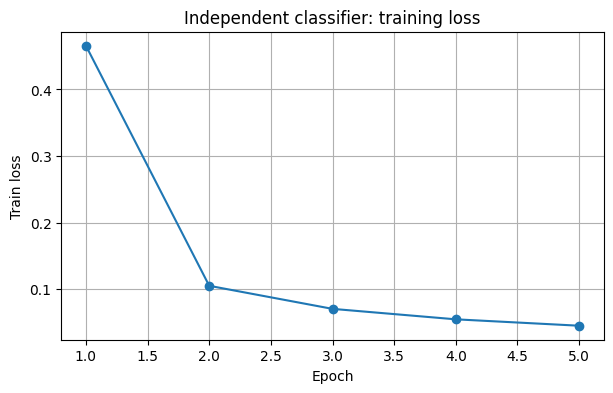

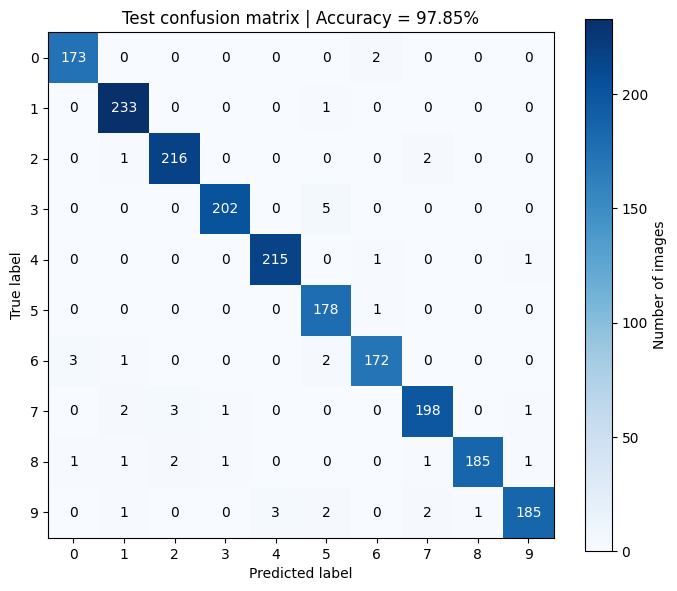

Test accuracy: 97.8500%
Test samples: 2000


In [9]:
# --------------------------------------------------
# 1. График train loss
# --------------------------------------------------
train_losses = [item['train_loss'] for item in classifier_history]

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(train_losses) + 1), train_losses, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Train loss')
plt.title('Independent classifier: training loss')
plt.grid(True)
plt.show()


# --------------------------------------------------
# 2. Матрица ошибок на test
# --------------------------------------------------
classifier.eval()

all_predictions = []
all_targets = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        logits = classifier(images)
        predictions = logits.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_targets.extend(labels.numpy())

all_predictions = np.array(all_predictions)
all_targets = np.array(all_targets)

confusion = np.zeros((10, 10), dtype=np.int64)
np.add.at(confusion, (all_targets, all_predictions), 1)

test_accuracy = np.trace(confusion) / confusion.sum()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(confusion, cmap='Blues')

ax.set_title(f'Test confusion matrix | Accuracy = {test_accuracy:.2%}')
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_xticks(range(10))
ax.set_yticks(range(10))

for i in range(10):
    for j in range(10):
        ax.text(j, i, str(confusion[i, j]),
                ha='center', va='center',
                color='white' if confusion[i, j] > confusion.max() * 0.5 else 'black')

plt.colorbar(im, ax=ax, label='Number of images')
plt.tight_layout()
plt.show()

print(f'Test accuracy: {test_accuracy:.4%}')
print(f'Test samples: {confusion.sum()}')

### Сбалансированные классы и общий шум

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Создайте сбалансированные классы и фиксированный исходный шум для всех весов CFG.

**Результат.** Проверяемое состояние «Сбалансированные классы и общий шум» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Создайте сбалансированные классы и фиксированный исходный шум для всех весов CFG» и его результат доступен следующему этапу.

In [10]:
# --------------------------------------------------
# Конфигурация набора для сравнения CFG
# --------------------------------------------------
NUM_SAMPLES_PER_CLASS = 100
NUM_CLASSES = 10
NUM_GENERATION_SAMPLES = NUM_SAMPLES_PER_CLASS * NUM_CLASSES

GENERATION_SEED = SEED + 17

# --------------------------------------------------
# Сбалансированные метки:
# 0 — 100 раз, 1 — 100 раз, ..., 9 — 100 раз
# --------------------------------------------------
generation_labels = torch.arange(
    NUM_CLASSES,
    dtype=torch.long
).repeat_interleave(NUM_SAMPLES_PER_CLASS)

# Отдельный генератор: его состояние не зависит от
# случайных операций, выполнявшихся ранее в notebook.
noise_generator = torch.Generator(device='cpu')
noise_generator.manual_seed(GENERATION_SEED)

# Один фиксированный начальный шум для каждого примера.
# Форма соответствует входу TinyDenoiser: [B, 1, 28, 28].
fixed_initial_noise = torch.randn(
    NUM_GENERATION_SAMPLES,
    1,
    28,
    28,
    generator=noise_generator,
    dtype=torch.float32
)

# Проверки сбалансированности и формы
class_counts = torch.bincount(
    generation_labels,
    minlength=NUM_CLASSES
)

assert generation_labels.shape == (NUM_GENERATION_SAMPLES,)
assert fixed_initial_noise.shape == (NUM_GENERATION_SAMPLES, 1, 28, 28)
assert torch.all(class_counts == NUM_SAMPLES_PER_CLASS)
assert torch.isfinite(fixed_initial_noise).all()

# Сохраняем на CPU: при генерации перенесём на DEVICE.
GENERATION_DATA_PATH = ARTIFACTS / 'cfg_balanced_generation_data.pt'

torch.save({
    'labels': generation_labels,
    'initial_noise': fixed_initial_noise,
    'num_samples_per_class': NUM_SAMPLES_PER_CLASS,
    'num_classes': NUM_CLASSES,
    'seed': GENERATION_SEED,
    'image_shape': [1, 28, 28]
}, GENERATION_DATA_PATH)

# Дополнительно сохраняем компактный NPZ для проверки
np.savez_compressed(
    ARTIFACTS / 'cfg_balanced_generation_data.npz',
    labels=generation_labels.numpy(),
    initial_noise=fixed_initial_noise.numpy(),
    seed=np.array(GENERATION_SEED),
    num_samples_per_class=np.array(NUM_SAMPLES_PER_CLASS)
)

generation_data_metrics = {
    'status': 'completed',
    'task': 'balanced_classes_and_shared_noise',
    'num_classes': NUM_CLASSES,
    'num_samples_per_class': NUM_SAMPLES_PER_CLASS,
    'total_samples': NUM_GENERATION_SAMPLES,
    'class_counts': class_counts.tolist(),
    'labels_shape': list(generation_labels.shape),
    'initial_noise_shape': list(fixed_initial_noise.shape),
    'initial_noise_mean': float(fixed_initial_noise.mean()),
    'initial_noise_std': float(fixed_initial_noise.std()),
    'initial_noise_min': float(fixed_initial_noise.min()),
    'initial_noise_max': float(fixed_initial_noise.max()),
    'seed': GENERATION_SEED,
    'same_noise_for_all_guidance_scales': True,
    'artifacts': [
        str(GENERATION_DATA_PATH),
        str(ARTIFACTS / 'cfg_balanced_generation_data.npz')
    ]
}

save_json(
    'task17_6_balanced_generation_data_metrics.json',
    generation_data_metrics
)

print('Сбалансированный набор создан.')
print(f'Всего примеров: {NUM_GENERATION_SAMPLES}')
print(f'Примеров на класс: {NUM_SAMPLES_PER_CLASS}')
print(f'Распределение классов: {class_counts.tolist()}')
print(f'Форма меток: {tuple(generation_labels.shape)}')
print(f'Форма начального шума: {tuple(fixed_initial_noise.shape)}')
print(f'Среднее начального шума: {fixed_initial_noise.mean().item():.6f}')
print(f'STD начального шума: {fixed_initial_noise.std().item():.6f}')
print(f'Файл: {GENERATION_DATA_PATH}')

Сбалансированный набор создан.
Всего примеров: 1000
Примеров на класс: 100
Распределение классов: [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]
Форма меток: (1000,)
Форма начального шума: (1000, 1, 28, 28)
Среднее начального шума: -0.000367
STD начального шума: 1.000188
Файл: /content/drive/MyDrive/lab17/artifacts/cfg_balanced_generation_data.pt


### DDPM sampling и guidance

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сэмплируйте обученной сетью при разных CFG; учитывайте conditional/unconditional NFE.

**Результат.** Проверяемое состояние «DDPM sampling и guidance» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сэмплируйте обученной сетью при разных CFG; учитывайте conditional/unconditional NFE» и его результат доступен следующему этапу.

In [11]:
# --------------------------------------------------
# Настройки генерации
# --------------------------------------------------
GUIDANCE_SCALES = [0.0, 1.0, 3.0, 5.0]

SAMPLES_PER_CLASS = 2 if FAST_DEV_RUN else NUM_SAMPLES_PER_CLASS
NUM_CLASSES = 10
NUM_SAMPLING_IMAGES = SAMPLES_PER_CLASS * NUM_CLASSES

SAMPLING_BATCH_SIZE = 20 if FAST_DEV_RUN else 64
SAMPLING_SEED = SEED + 123

MODE_NAME = 'smoke' if FAST_DEV_RUN else 'full'


# --------------------------------------------------
# CFG: два прохода одной и той же сетью
# --------------------------------------------------
def guided_eps(model, x_t, t, labels, guidance_scale):
    """
    Classifier-Free Guidance:
    eps = eps_uncond + w * (eps_cond - eps_uncond)
    """
    null_labels = torch.full_like(labels, 10)

    eps_uncond = model(x_t, t, null_labels)
    eps_cond = model(x_t, t, labels)

    eps_guided = eps_uncond + guidance_scale * (
        eps_cond - eps_uncond
    )

    return eps_guided


# --------------------------------------------------
# Один шаг обратного процесса DDPM
# --------------------------------------------------
def ddpm_reverse_step(x_t, t, predicted_noise, schedule, generator=None):
    """
    Один шаг: x_t -> x_{t-1}.
    Используется posterior variance DDPM.
    """
    beta_t = schedule['beta'][t]
    alpha_t = schedule['alpha'][t]
    alpha_bar_t = schedule['alpha_bar'][t]

    if t > 0:
        alpha_bar_prev = schedule['alpha_bar'][t - 1]
    else:
        alpha_bar_prev = torch.tensor(
            1.0, device=x_t.device, dtype=x_t.dtype
        )

    # Среднее обратного распределения
    mean = (
        x_t - beta_t / torch.sqrt(1.0 - alpha_bar_t) * predicted_noise
    ) / torch.sqrt(alpha_t)

    # Дисперсия posterior q(x_{t-1} | x_t, x_0)
    posterior_variance = (
        beta_t * (1.0 - alpha_bar_prev) / (1.0 - alpha_bar_t)
    )

    if t > 0:
        noise = torch.randn(
            x_t.shape,
            device=x_t.device,
            dtype=x_t.dtype,
            generator=generator
        )
        x_prev = mean + torch.sqrt(posterior_variance.clamp(min=1e-20)) * noise
    else:
        x_prev = mean

    return x_prev


# --------------------------------------------------
# Полный DDPM sampling с CFG
# --------------------------------------------------
def ddpm_sample(model, labels, initial_noise, guidance_scale, schedule, generator):
    """
    Генерация изображений от x_T до x_0.

    На каждом timestep выполняются два прохода модели:
    unconditional + conditional.
    """
    model.eval()

    x = initial_noise.clone().to(DEVICE)
    labels = labels.to(DEVICE)

    batch_size = x.shape[0]
    num_steps = schedule['beta'].shape[0]

    with torch.no_grad():
        for t_value in reversed(range(num_steps)):
            t_batch = torch.full(
                (batch_size,),
                t_value,
                device=DEVICE,
                dtype=torch.long
            )

            predicted_noise = guided_eps(
                model=model,
                x_t=x,
                t=t_batch,
                labels=labels,
                guidance_scale=guidance_scale
            )

            x = ddpm_reverse_step(
                x_t=x,
                t=t_value,
                predicted_noise=predicted_noise,
                schedule=schedule,
                generator=generator
            )

    return x.clamp(-1.0, 1.0)


# --------------------------------------------------
# Подготавливаем сбалансированный поднабор
# --------------------------------------------------
selected_indices = []

for digit in range(NUM_CLASSES):
    digit_indices = torch.where(generation_labels == digit)[0]
    selected_indices.extend(digit_indices[:SAMPLES_PER_CLASS].tolist())

selected_indices = torch.tensor(selected_indices, dtype=torch.long)

sampling_labels = generation_labels[selected_indices]
sampling_initial_noise = fixed_initial_noise[selected_indices]

assert len(sampling_labels) == NUM_SAMPLING_IMAGES
assert torch.all(
    torch.bincount(sampling_labels, minlength=10) == SAMPLES_PER_CLASS
)

# --------------------------------------------------
# Генерация для каждого guidance scale
# --------------------------------------------------
generated_samples = {}
sampling_metrics = {}

model.eval()
sampling_start_time = time.time()

for guidance_scale in GUIDANCE_SCALES:
    print(f'\nГенерация: CFG = {guidance_scale}')

    generated_batches = []

    # Для каждого CFG используем один и тот же seed.
    # Поэтому случайные шумы обратного процесса совпадают.
    reverse_generator = torch.Generator(device=DEVICE)
    reverse_generator.manual_seed(SAMPLING_SEED)

    scale_start_time = time.time()

    for start in range(0, NUM_SAMPLING_IMAGES, SAMPLING_BATCH_SIZE):
        end = min(start + SAMPLING_BATCH_SIZE, NUM_SAMPLING_IMAGES)

        batch_noise = sampling_initial_noise[start:end]
        batch_labels = sampling_labels[start:end]

        batch_images = ddpm_sample(
            model=model,
            labels=batch_labels,
            initial_noise=batch_noise,
            guidance_scale=guidance_scale,
            schedule=SCHEDULE,
            generator=reverse_generator
        )

        generated_batches.append(batch_images.cpu())

    scale_images = torch.cat(generated_batches, dim=0)
    generated_samples[guidance_scale] = scale_images

    scale_time = time.time() - scale_start_time

    # Два вызова сети на каждом timestep
    nfe_per_image = 2 * T
    total_nfe = nfe_per_image * NUM_SAMPLING_IMAGES

    sampling_metrics[str(guidance_scale)] = {
        'guidance_scale': guidance_scale,
        'num_images': NUM_SAMPLING_IMAGES,
        'num_diffusion_steps': T,
        'unconditional_nfe_per_image': T,
        'conditional_nfe_per_image': T,
        'total_nfe_per_image': nfe_per_image,
        'total_nfe': total_nfe,
        'sampling_time_seconds': float(scale_time),
        'images_shape': list(scale_images.shape)
    }

    print(f'Изображений: {len(scale_images)}')
    print(f'NFE на изображение: {nfe_per_image}')
    print(f'Общее число NFE: {total_nfe}')
    print(f'Время: {scale_time:.2f} сек.')

total_sampling_time = time.time() - sampling_start_time

# --------------------------------------------------
# Сохраняем результаты генерации
# --------------------------------------------------
GENERATION_CHECKPOINT = ARTIFACTS / f'ddpm_generated_{MODE_NAME}.pt'

torch.save({
    'generated_samples': generated_samples,
    'labels': sampling_labels,
    'initial_noise': sampling_initial_noise,
    'guidance_scales': GUIDANCE_SCALES,
    'sampling_metrics': sampling_metrics,
    'fast_dev_run': FAST_DEV_RUN,
    'seed': SAMPLING_SEED
}, GENERATION_CHECKPOINT)

sampling_summary = {
    'status': 'completed',
    'task': 'ddpm_sampling_and_guidance',
    'fast_dev_run': FAST_DEV_RUN,
    'device': DEVICE,
    'guidance_scales': GUIDANCE_SCALES,
    'num_images_per_scale': NUM_SAMPLING_IMAGES,
    'samples_per_class': SAMPLES_PER_CLASS,
    'class_counts': torch.bincount(sampling_labels, minlength=10).tolist(),
    'same_initial_noise_for_all_scales': True,
    'same_reverse_noise_seed_for_all_scales': True,
    'metrics_by_guidance': sampling_metrics,
    'total_sampling_time_seconds': float(total_sampling_time),
    'checkpoint': str(GENERATION_CHECKPOINT)
}

save_json('task17_7_sampling_metrics.json', sampling_summary)

print('\nГенерация завершена.')
print(f'CFG scales: {GUIDANCE_SCALES}')
print(f'Изображений на каждый CFG: {NUM_SAMPLING_IMAGES}')
print(f'Общее время: {total_sampling_time:.2f} сек.')
print(f'Результаты: {GENERATION_CHECKPOINT}')


Генерация: CFG = 0.0
Изображений: 1000
NFE на изображение: 2000
Общее число NFE: 2000000
Время: 334.38 сек.

Генерация: CFG = 1.0
Изображений: 1000
NFE на изображение: 2000
Общее число NFE: 2000000
Время: 339.69 сек.

Генерация: CFG = 3.0
Изображений: 1000
NFE на изображение: 2000
Общее число NFE: 2000000
Время: 339.07 сек.

Генерация: CFG = 5.0
Изображений: 1000
NFE на изображение: 2000
Общее число NFE: 2000000
Время: 338.31 сек.

Генерация завершена.
CFG scales: [0.0, 1.0, 3.0, 5.0]
Изображений на каждый CFG: 1000
Общее время: 1351.45 сек.
Результаты: /content/drive/MyDrive/lab17/artifacts/ddpm_generated_full.pt


### Сохранение измерений генерации

*Вес: 1 балл.*

**Постановка.** Сравнение guidance требует одинаковых начального шума и генератора для каждой шкалы. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните метрики, изображения и точность проверяющего классификатора на test.

**Результат.** Проверяемое состояние «Сохранение измерений генерации» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните метрики, изображения и точность проверяющего классификатора на test» и его результат доступен следующему этапу.

CFG=0.0: accuracy=11.6000% (116/1000)
CFG=1.0: accuracy=23.7000% (237/1000)
CFG=3.0: accuracy=43.2000% (432/1000)
CFG=5.0: accuracy=52.3000% (523/1000)

Classifier accuracy on real MNIST test: 97.8500%


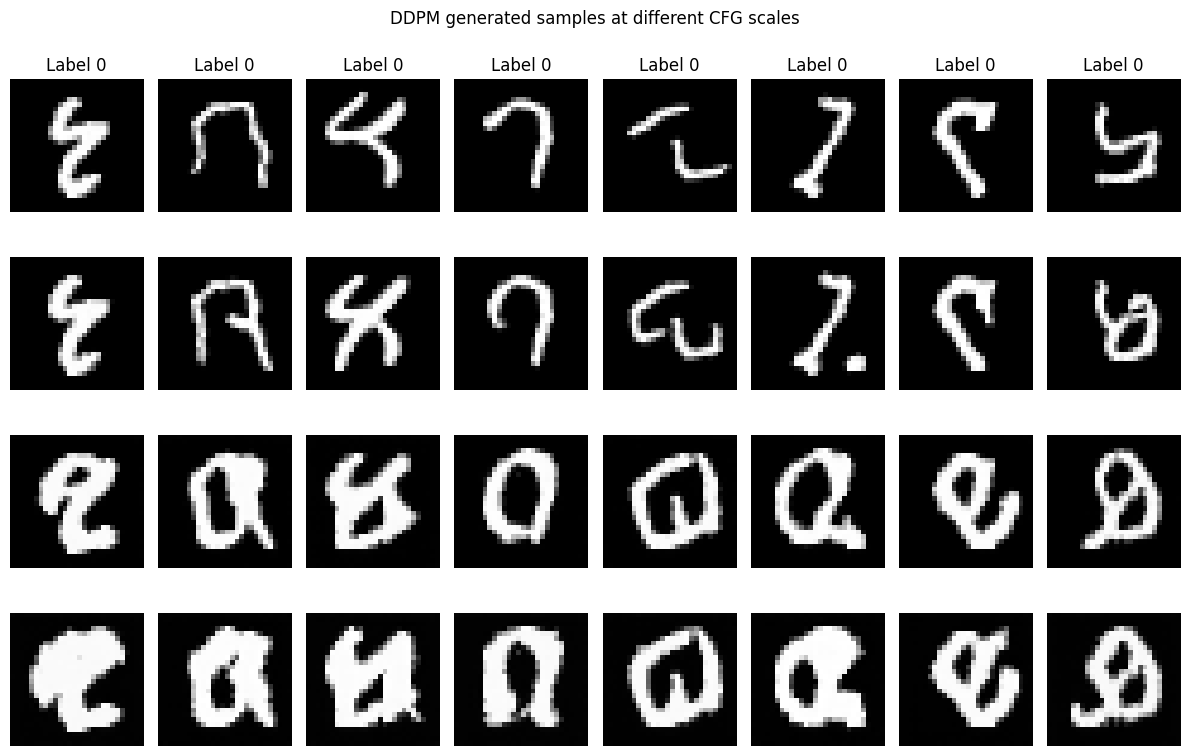

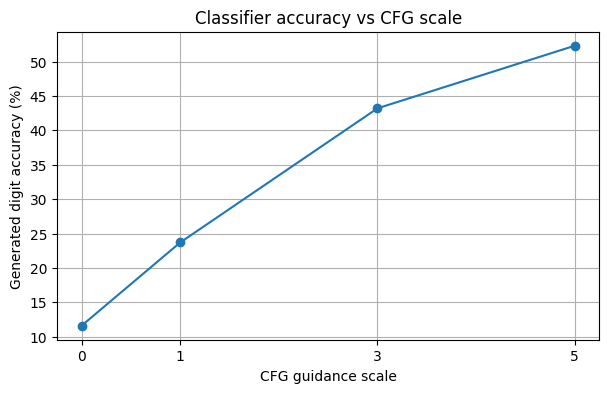


Итоговые результаты:
CFG=0.0: 11.60% (116/1000)
CFG=1.0: 23.70% (237/1000)
CFG=3.0: 43.20% (432/1000)
CFG=5.0: 52.30% (523/1000)
Real test accuracy: 97.85%
Изображения: /content/drive/MyDrive/lab17/artifacts/ddpm_generation_grid_full.png
График accuracy: /content/drive/MyDrive/lab17/artifacts/ddpm_cfg_accuracy_full.png
Метрики: /content/drive/MyDrive/lab17/artifacts/task17_8_generation_measurements.json


In [12]:
# --------------------------------------------------
# Проверка независимым классификатором
# --------------------------------------------------
classifier.eval()

generation_evaluation = {}

for guidance_scale, images_cpu in generated_samples.items():
    images = images_cpu.to(DEVICE)
    labels = sampling_labels.to(DEVICE)

    all_predictions = []

    with torch.no_grad():
        for start in range(0, len(images), 128):
            batch = images[start:start + 128]
            logits = classifier(batch)
            predictions = logits.argmax(dim=1)
            all_predictions.append(predictions.cpu())

    predictions = torch.cat(all_predictions)
    targets = sampling_labels.cpu()

    accuracy = (predictions == targets).float().mean().item()

    confusion = torch.zeros(10, 10, dtype=torch.int64)
    for true_label, predicted_label in zip(targets, predictions):
        confusion[true_label, predicted_label] += 1

    generation_evaluation[str(guidance_scale)] = {
        'guidance_scale': guidance_scale,
        'accuracy': float(accuracy),
        'correct': int((predictions == targets).sum().item()),
        'total': int(len(targets)),
        'confusion_matrix': confusion.tolist()
    }

    print(
        f'CFG={guidance_scale}: '
        f'accuracy={accuracy:.4%} '
        f'({int((predictions == targets).sum())}/{len(targets)})'
    )


# --------------------------------------------------
# Реальная test accuracy классификатора
# --------------------------------------------------
classifier.eval()
real_test_correct = 0
real_test_total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        predictions = classifier(images).argmax(dim=1)
        real_test_correct += (predictions == labels).sum().item()
        real_test_total += labels.size(0)

real_test_accuracy = real_test_correct / real_test_total

print(f'\nClassifier accuracy on real MNIST test: {real_test_accuracy:.4%}')


# --------------------------------------------------
# Сохраняем изображения и оценки
# --------------------------------------------------
EVALUATION_PATH = ARTIFACTS / f'ddpm_evaluation_{MODE_NAME}.pt'

torch.save({
    'generated_samples': generated_samples,
    'labels': sampling_labels,
    'evaluation': generation_evaluation,
    'real_test_accuracy': real_test_accuracy,
    'real_test_samples': real_test_total,
    'guidance_scales': GUIDANCE_SCALES
}, EVALUATION_PATH)

# --------------------------------------------------
# Визуализация: сетка примеров по CFG
# --------------------------------------------------
NUM_SHOW = min(8, NUM_SAMPLING_IMAGES)

fig, axes = plt.subplots(
    len(GUIDANCE_SCALES),
    NUM_SHOW,
    figsize=(NUM_SHOW * 1.5, len(GUIDANCE_SCALES) * 2)
)

for row, guidance_scale in enumerate(GUIDANCE_SCALES):
    samples = generated_samples[guidance_scale]

    for col in range(NUM_SHOW):
        image = samples[col].squeeze().numpy()
        axes[row, col].imshow(image, cmap='gray', vmin=-1, vmax=1)
        axes[row, col].axis('off')

        if row == 0:
            axes[row, col].set_title(f'Label {sampling_labels[col].item()}')

    axes[row, 0].set_ylabel(
        f'CFG={guidance_scale}',
        rotation=90,
        size='large'
    )

plt.suptitle('DDPM generated samples at different CFG scales')
plt.tight_layout()

GENERATION_GRID_PATH = ARTIFACTS / f'ddpm_generation_grid_{MODE_NAME}.png'
plt.savefig(GENERATION_GRID_PATH, dpi=150, bbox_inches='tight')
plt.show()


# --------------------------------------------------
# Визуализация: accuracy в зависимости от CFG
# --------------------------------------------------
cfg_values = [str(x) for x in GUIDANCE_SCALES]
accuracies = [
    generation_evaluation[x]['accuracy'] * 100
    for x in cfg_values
]

plt.figure(figsize=(7, 4))
plt.plot(
    [float(x) for x in cfg_values],
    accuracies,
    marker='o'
)
plt.xlabel('CFG guidance scale')
plt.ylabel('Generated digit accuracy (%)')
plt.title('Classifier accuracy vs CFG scale')
plt.xticks([float(x) for x in cfg_values])
plt.grid(True)

ACCURACY_PLOT_PATH = ARTIFACTS / f'ddpm_cfg_accuracy_{MODE_NAME}.png'
plt.savefig(ACCURACY_PLOT_PATH, dpi=150, bbox_inches='tight')
plt.show()


# --------------------------------------------------
# JSON с итоговыми метриками
# --------------------------------------------------
generation_measurements = {
    'status': 'completed',
    'task': 'generation_measurements',
    'fast_dev_run': FAST_DEV_RUN,
    'real_mnist_test_accuracy': float(real_test_accuracy),
    'real_mnist_test_samples': real_test_total,
    'generated_samples_per_guidance': NUM_SAMPLING_IMAGES,
    'generation_metrics': generation_evaluation,
    'artifacts': {
        'evaluation_checkpoint': str(EVALUATION_PATH),
        'generation_grid': str(GENERATION_GRID_PATH),
        'accuracy_plot': str(ACCURACY_PLOT_PATH)
    }
}

save_json(
    'task17_8_generation_measurements.json',
    generation_measurements
)

print('\nИтоговые результаты:')

for cfg in GUIDANCE_SCALES:
    result = generation_evaluation[str(cfg)]
    print(
        f"CFG={cfg}: "
        f"{result['accuracy']:.2%} "
        f"({result['correct']}/{result['total']})"
    )

print(f'Real test accuracy: {real_test_accuracy:.2%}')
print(f'Изображения: {GENERATION_GRID_PATH}')
print(f'График accuracy: {ACCURACY_PLOT_PATH}')
print(f'Метрики: {ARTIFACTS / "task17_8_generation_measurements.json"}')

In [16]:
# ============================================================
# Accuracy per class for CFG guidance_scale = 5.0
# ============================================================

TARGET_W = 5.0

# Получаем сгенерированные изображения для w=5.0.
# В задании 7 результаты сохранены в словаре generated_samples.
samples_w5 = generated_samples[TARGET_W]

classifier.eval()

with torch.no_grad():
    samples_w5 = samples_w5.to(DEVICE)
    true_labels_w5 = generation_labels.to(DEVICE)

    logits = classifier(samples_w5)
    predicted_labels_w5 = logits.argmax(dim=1)

# Accuracy для каждого класса
class_accuracy_rows = []

for digit in range(10):
    class_mask = true_labels_w5 == digit

    total = class_mask.sum().item()

    correct = (
        predicted_labels_w5[class_mask]
        == true_labels_w5[class_mask]
    ).sum().item()

    accuracy = correct / total if total > 0 else float("nan")

    class_accuracy_rows.append({
        "Digit": digit,
        "Correct": correct,
        "Total": total,
        "Accuracy (%)": accuracy * 100
    })

accuracy_w5_table = pd.DataFrame(class_accuracy_rows)

print("Classifier accuracy per digit (CFG w=5.0):")

display(
    accuracy_w5_table.style.format({
        "Accuracy (%)": "{:.2f}%"
    })
)

# Общая accuracy
overall_accuracy_w5 = (
    predicted_labels_w5 == true_labels_w5
).float().mean().item()

print(
    f"\nOverall accuracy for w=5.0: "
    f"{overall_accuracy_w5 * 100:.2f}%"
)

# Сохранение результатов
accuracy_w5_results = {
    "guidance_scale": TARGET_W,
    "overall_accuracy": overall_accuracy_w5,
    "per_class_accuracy": {
        str(row["Digit"]): row["Accuracy (%)"] / 100
        for row in class_accuracy_rows
    },
    "per_class_correct": {
        str(row["Digit"]): row["Correct"]
        for row in class_accuracy_rows
    },
    "per_class_total": {
        str(row["Digit"]): row["Total"]
        for row in class_accuracy_rows
    }
}

save_json(
    "task17_accuracy_per_class_w5.json",
    accuracy_w5_results
)

accuracy_w5_table.to_csv(
    ARTIFACTS / "task17_accuracy_per_class_w5.csv",
    index=False
)

print("\nResults saved:")
print(ARTIFACTS / "task17_accuracy_per_class_w5.json")
print(ARTIFACTS / "task17_accuracy_per_class_w5.csv")

Classifier accuracy per digit (CFG w=5.0):


,Digit,Correct,Total,Accuracy (%)
0,0,71,100,71.00%
1,1,58,100,58.00%
2,2,78,100,78.00%
3,3,78,100,78.00%
4,4,37,100,37.00%
5,5,60,100,60.00%
6,6,27,100,27.00%
7,7,30,100,30.00%
8,8,81,100,81.00%
9,9,3,100,3.00%



Overall accuracy for w=5.0: 52.30%

Results saved:
/content/drive/MyDrive/lab17/artifacts/task17_accuracy_per_class_w5.json
/content/drive/MyDrive/lab17/artifacts/task17_accuracy_per_class_w5.csv


### Шумовая ошибка на разных временах

*Вес: 1 балл.*

**Постановка.** Выбор T и schedule влияет на величину остаточного сигнала, а метрика MSE по отложенным изображениям проверяет предсказатель непосредственно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте conditional/unconditional MSE по фиксированному test batch на нескольких timesteps.

**Результат.** Проверяемое состояние «Шумовая ошибка на разных временах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте conditional/unconditional MSE по фиксированному test batch на нескольких timesteps» и его результат доступен следующему этапу.

t=   0 | conditional MSE=0.174335 | unconditional MSE=0.173798
t=  50 | conditional MSE=0.083134 | unconditional MSE=0.083408
t= 100 | conditional MSE=0.057456 | unconditional MSE=0.058267
t= 250 | conditional MSE=0.032446 | unconditional MSE=0.033746
t= 500 | conditional MSE=0.015114 | unconditional MSE=0.016173
t= 750 | conditional MSE=0.001041 | unconditional MSE=0.001025
t= 999 | conditional MSE=0.000274 | unconditional MSE=0.000240


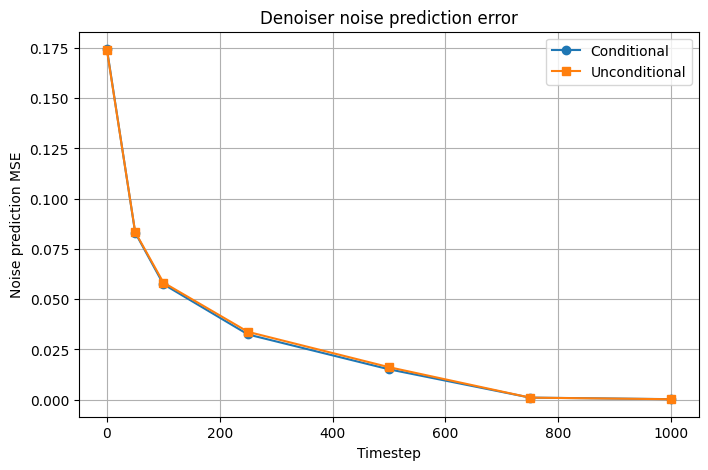


Артефакты:
/content/drive/MyDrive/lab17/artifacts/task17_9_noise_error_by_timestep.json
/content/drive/MyDrive/lab17/artifacts/noise_error_by_timestep_full.png


In [13]:
# --------------------------------------------------
# Настройки эксперимента
# --------------------------------------------------
EVAL_TIMESTEPS = [0, 50, 100, 250, 500, 750, 999]
EVAL_TIMESTEPS = [t for t in EVAL_TIMESTEPS if t < T]

EVAL_SEED = SEED + 501
MODE_NAME = 'smoke' if FAST_DEV_RUN else 'full'

# Один фиксированный batch из test
test_images, test_labels = next(iter(test_loader))
test_images = test_images.to(DEVICE)
test_labels = test_labels.to(DEVICE)

# Фиксированный шум для всех timesteps и обоих режимов
noise_generator = torch.Generator(device='cpu')
noise_generator.manual_seed(EVAL_SEED)

fixed_test_noise = torch.randn(
    test_images.shape,
    generator=noise_generator,
    dtype=torch.float32
).to(DEVICE)

null_labels = torch.full_like(test_labels, 10)

# --------------------------------------------------
# Оценка conditional / unconditional MSE
# --------------------------------------------------
model.eval()

noise_error_results = {}

with torch.no_grad():
    for timestep in EVAL_TIMESTEPS:
        t_batch = torch.full(
            (test_images.size(0),),
            timestep,
            device=DEVICE,
            dtype=torch.long
        )

        noisy_images = q_sample(
            test_images,
            t_batch,
            noise=fixed_test_noise,
            schedule=SCHEDULE
        )

        # Условное предсказание: настоящие метки цифр
        predicted_cond = model(
            noisy_images,
            t_batch,
            test_labels
        )

        # Безусловное предсказание: null class = 10
        predicted_uncond = model(
            noisy_images,
            t_batch,
            null_labels
        )

        conditional_mse = F.mse_loss(
            predicted_cond,
            fixed_test_noise
        ).item()

        unconditional_mse = F.mse_loss(
            predicted_uncond,
            fixed_test_noise
        ).item()

        noise_error_results[str(timestep)] = {
            'timestep': timestep,
            'conditional_mse': float(conditional_mse),
            'unconditional_mse': float(unconditional_mse)
        }

        print(
            f't={timestep:4d} | '
            f'conditional MSE={conditional_mse:.6f} | '
            f'unconditional MSE={unconditional_mse:.6f}'
        )

# --------------------------------------------------
# Сохранение результатов
# --------------------------------------------------
noise_error_metrics = {
    'status': 'completed',
    'task': 'noise_prediction_error_by_timestep',
    'fast_dev_run': FAST_DEV_RUN,
    'test_batch_size': int(test_images.size(0)),
    'test_labels': test_labels.cpu().tolist(),
    'timesteps': EVAL_TIMESTEPS,
    'seed': EVAL_SEED,
    'results': noise_error_results
}

save_json(
    'task17_9_noise_error_by_timestep.json',
    noise_error_metrics
)

# --------------------------------------------------
# График MSE по timestep
# --------------------------------------------------
conditional_values = [
    noise_error_results[str(t)]['conditional_mse']
    for t in EVAL_TIMESTEPS
]

unconditional_values = [
    noise_error_results[str(t)]['unconditional_mse']
    for t in EVAL_TIMESTEPS
]

plt.figure(figsize=(8, 5))
plt.plot(
    EVAL_TIMESTEPS,
    conditional_values,
    marker='o',
    label='Conditional'
)
plt.plot(
    EVAL_TIMESTEPS,
    unconditional_values,
    marker='s',
    label='Unconditional'
)

plt.xlabel('Timestep')
plt.ylabel('Noise prediction MSE')
plt.title('Denoiser noise prediction error')
plt.legend()
plt.grid(True)

NOISE_ERROR_PLOT = ARTIFACTS / f'noise_error_by_timestep_{MODE_NAME}.png'
plt.savefig(NOISE_ERROR_PLOT, dpi=150, bbox_inches='tight')
plt.show()

print('\nАртефакты:')
print(ARTIFACTS / 'task17_9_noise_error_by_timestep.json')
print(NOISE_ERROR_PLOT)

### Худшие ошибки denoiser

*Вес: 1 балл.*

**Постановка.** Выбор T и schedule влияет на величину остаточного сигнала, а метрика MSE по отложенным изображениям проверяет предсказатель непосредственно. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Зафиксируйте реальные ошибки и пять худших test изображений.

**Результат.** Проверяемое состояние «Худшие ошибки denoiser» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Зафиксируйте реальные ошибки и пять худших test изображений» и его результат доступен следующему этапу.

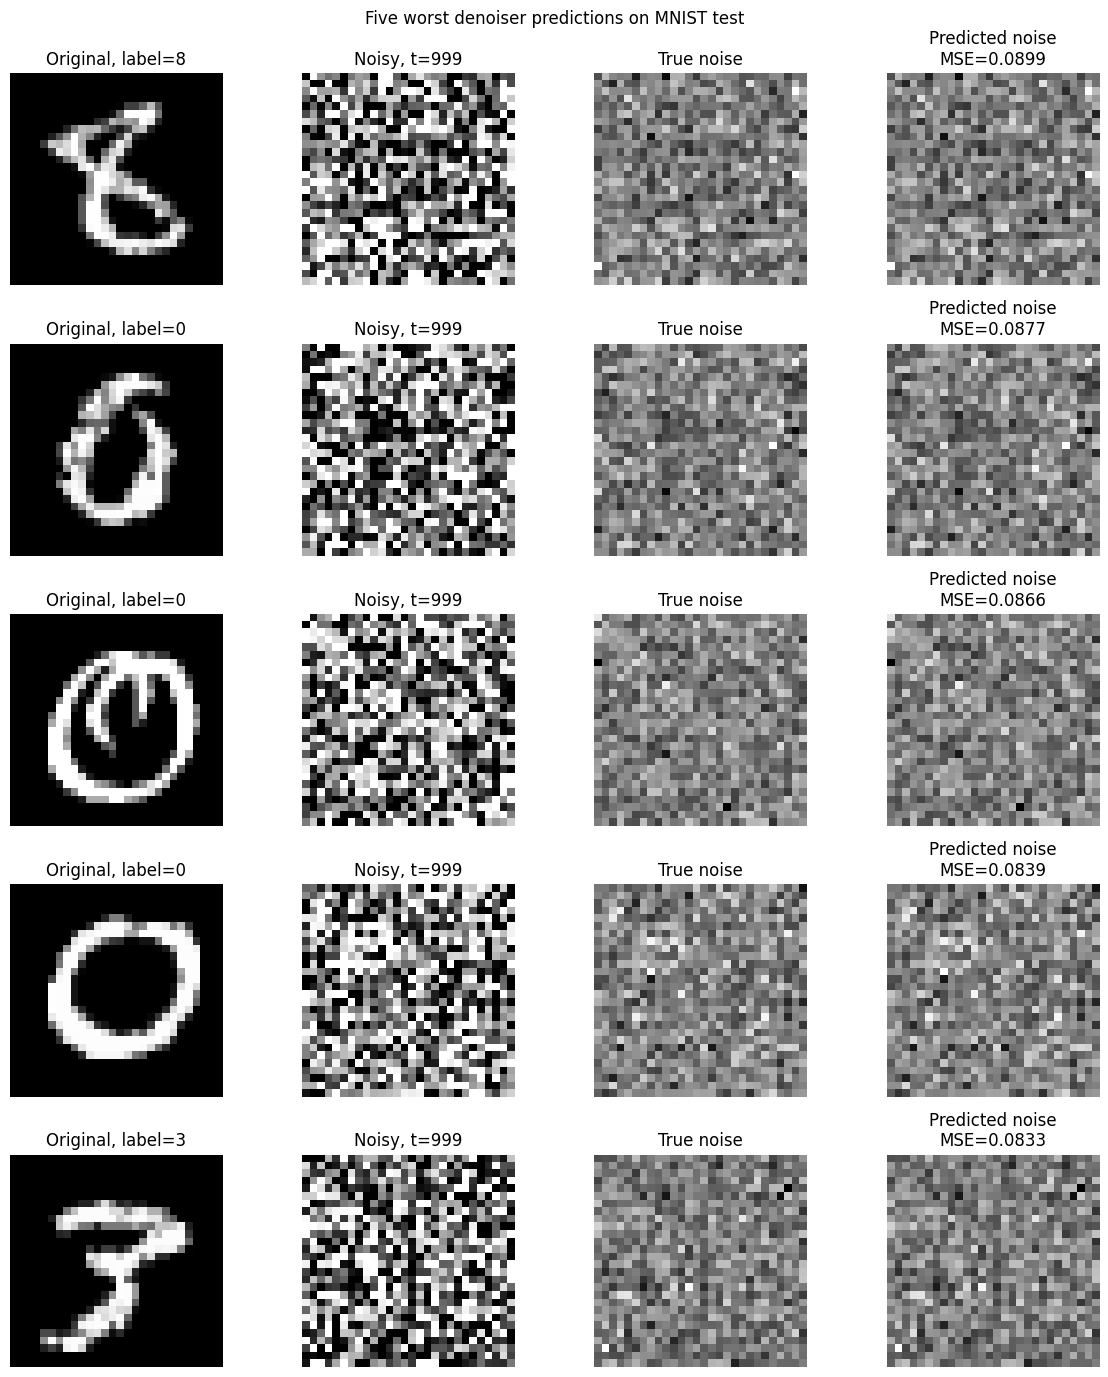


Пять худших test изображений:
Index=1415 | Label=8 | Mean MSE=0.089886
Index=1438 | Label=0 | Mean MSE=0.087666
Index=1526 | Label=0 | Mean MSE=0.086591
Index=1589 | Label=0 | Mean MSE=0.083881
Index= 464 | Label=3 | Mean MSE=0.083340

Средний MSE по test: 0.048045
Максимальный MSE: 0.089886
Минимальный MSE: 0.016251

Артефакты:
/content/drive/MyDrive/lab17/artifacts/denoiser_worst_errors_full.pt
/content/drive/MyDrive/lab17/artifacts/denoiser_worst_errors_full.png
/content/drive/MyDrive/lab17/artifacts/task17_10_worst_denoiser_errors.json


In [14]:
# --------------------------------------------------
# Настройки
# --------------------------------------------------
WORST_TIMESTEPS = [0, 100, 250, 500, 750, 999]
WORST_TIMESTEPS = [t for t in WORST_TIMESTEPS if t < T]

WORST_SEED = SEED + 502
NUM_WORST_IMAGES = 5
MODE_NAME = 'smoke' if FAST_DEV_RUN else 'full'

# Фиксированный генератор шума
worst_noise_generator = torch.Generator(device='cpu')
worst_noise_generator.manual_seed(WORST_SEED)

model.eval()

all_image_errors = []
all_image_labels = []
all_original_images = []
all_noisy_images = []
all_true_noises = []
all_predicted_noises = []

# --------------------------------------------------
# Проход по всему test-набору
# --------------------------------------------------
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        batch_size = images.size(0)

        # Один и тот же шум для всех timestep данного batch
        fixed_noise = torch.randn(
            images.shape,
            generator=worst_noise_generator,
            dtype=torch.float32
        ).to(DEVICE)

        per_image_errors = []

        # Сохраним визуальные данные на последнем timestep
        last_noisy = None
        last_true_noise = None
        last_predicted_noise = None

        for timestep in WORST_TIMESTEPS:
            t_batch = torch.full(
                (batch_size,),
                timestep,
                device=DEVICE,
                dtype=torch.long
            )

            noisy = q_sample(
                images,
                t_batch,
                noise=fixed_noise,
                schedule=SCHEDULE
            )

            predicted = model(noisy, t_batch, labels)

            # MSE отдельно для каждого изображения
            per_image_mse = (
                (predicted - fixed_noise) ** 2
            ).mean(dim=(1, 2, 3))

            per_image_errors.append(per_image_mse)

            last_noisy = noisy
            last_true_noise = fixed_noise
            last_predicted_noise = predicted

        # Средняя ошибка каждого изображения по timestep
        mean_image_errors = torch.stack(
            per_image_errors,
            dim=0
        ).mean(dim=0)

        all_image_errors.append(mean_image_errors.cpu())
        all_image_labels.append(labels.cpu())
        all_original_images.append(images.cpu())
        all_noisy_images.append(last_noisy.cpu())
        all_true_noises.append(last_true_noise.cpu())
        all_predicted_noises.append(last_predicted_noise.cpu())

# --------------------------------------------------
# Объединение результатов
# --------------------------------------------------
all_image_errors = torch.cat(all_image_errors)
all_image_labels = torch.cat(all_image_labels)
all_original_images = torch.cat(all_original_images)
all_noisy_images = torch.cat(all_noisy_images)
all_true_noises = torch.cat(all_true_noises)
all_predicted_noises = torch.cat(all_predicted_noises)

# Пять индексов с наибольшей средней ошибкой
worst_indices = torch.topk(
    all_image_errors,
    k=NUM_WORST_IMAGES,
    largest=True
).indices

worst_errors = all_image_errors[worst_indices]
worst_labels = all_image_labels[worst_indices]

worst_original = all_original_images[worst_indices]
worst_noisy = all_noisy_images[worst_indices]
worst_true_noise = all_true_noises[worst_indices]
worst_predicted_noise = all_predicted_noises[worst_indices]

# --------------------------------------------------
# Сохранение данных худших примеров
# --------------------------------------------------
WORST_CHECKPOINT = ARTIFACTS / f'denoiser_worst_errors_{MODE_NAME}.pt'

torch.save({
    'worst_indices_in_test': worst_indices,
    'worst_errors': worst_errors,
    'worst_labels': worst_labels,
    'original_images': worst_original,
    'noisy_images': worst_noisy,
    'true_noise': worst_true_noise,
    'predicted_noise': worst_predicted_noise,
    'timesteps': WORST_TIMESTEPS,
    'seed': WORST_SEED,
    'error_definition': 'mean conditional noise MSE over selected timesteps'
}, WORST_CHECKPOINT)

# --------------------------------------------------
# Визуализация пяти худших примеров
# --------------------------------------------------
fig, axes = plt.subplots(5, 4, figsize=(12, 14))

for i in range(NUM_WORST_IMAGES):
    original = worst_original[i].squeeze().numpy()
    noisy = worst_noisy[i].squeeze().numpy()
    true_noise = worst_true_noise[i].squeeze().numpy()
    predicted_noise = worst_predicted_noise[i].squeeze().numpy()

    axes[i, 0].imshow(original, cmap='gray', vmin=-1, vmax=1)
    axes[i, 0].set_title(
        f"Original, label={worst_labels[i].item()}"
    )

    axes[i, 1].imshow(noisy, cmap='gray', vmin=-1, vmax=1)
    axes[i, 1].set_title(f'Noisy, t={WORST_TIMESTEPS[-1]}')

    noise_limit = max(
        abs(true_noise.min()),
        abs(true_noise.max()),
        abs(predicted_noise.min()),
        abs(predicted_noise.max()),
        1e-6
    )

    axes[i, 2].imshow(
        true_noise,
        cmap='gray',
        vmin=-noise_limit,
        vmax=noise_limit
    )
    axes[i, 2].set_title('True noise')

    axes[i, 3].imshow(
        predicted_noise,
        cmap='gray',
        vmin=-noise_limit,
        vmax=noise_limit
    )
    axes[i, 3].set_title(
        f'Predicted noise\nMSE={worst_errors[i].item():.4f}'
    )

    for j in range(4):
        axes[i, j].axis('off')

plt.suptitle('Five worst denoiser predictions on MNIST test')
plt.tight_layout()

WORST_PLOT = ARTIFACTS / f'denoiser_worst_errors_{MODE_NAME}.png'
plt.savefig(WORST_PLOT, dpi=150, bbox_inches='tight')
plt.show()

# --------------------------------------------------
# JSON с метриками
# --------------------------------------------------
worst_error_metrics = {
    'status': 'completed',
    'task': 'worst_denoiser_errors',
    'fast_dev_run': FAST_DEV_RUN,
    'test_samples_evaluated': int(len(all_image_errors)),
    'timesteps': WORST_TIMESTEPS,
    'error_definition': 'mean conditional noise MSE over selected timesteps',
    'worst_examples': [
        {
            'test_index': int(worst_indices[i].item()),
            'true_label': int(worst_labels[i].item()),
            'mean_noise_mse': float(worst_errors[i].item())
        }
        for i in range(NUM_WORST_IMAGES)
    ],
    'mean_test_mse': float(all_image_errors.mean()),
    'max_test_mse': float(all_image_errors.max()),
    'min_test_mse': float(all_image_errors.min()),
    'checkpoint': str(WORST_CHECKPOINT),
    'visualization': str(WORST_PLOT)
}

save_json('task17_10_worst_denoiser_errors.json', worst_error_metrics)

print('\nПять худших test изображений:')
for item in worst_error_metrics['worst_examples']:
    print(
        f"Index={item['test_index']:4d} | "
        f"Label={item['true_label']} | "
        f"Mean MSE={item['mean_noise_mse']:.6f}"
    )

print(f"\nСредний MSE по test: {worst_error_metrics['mean_test_mse']:.6f}")
print(f"Максимальный MSE: {worst_error_metrics['max_test_mse']:.6f}")
print(f"Минимальный MSE: {worst_error_metrics['min_test_mse']:.6f}")

print('\nАртефакты:')
print(WORST_CHECKPOINT)
print(WORST_PLOT)
print(ARTIFACTS / 'task17_10_worst_denoiser_errors.json')

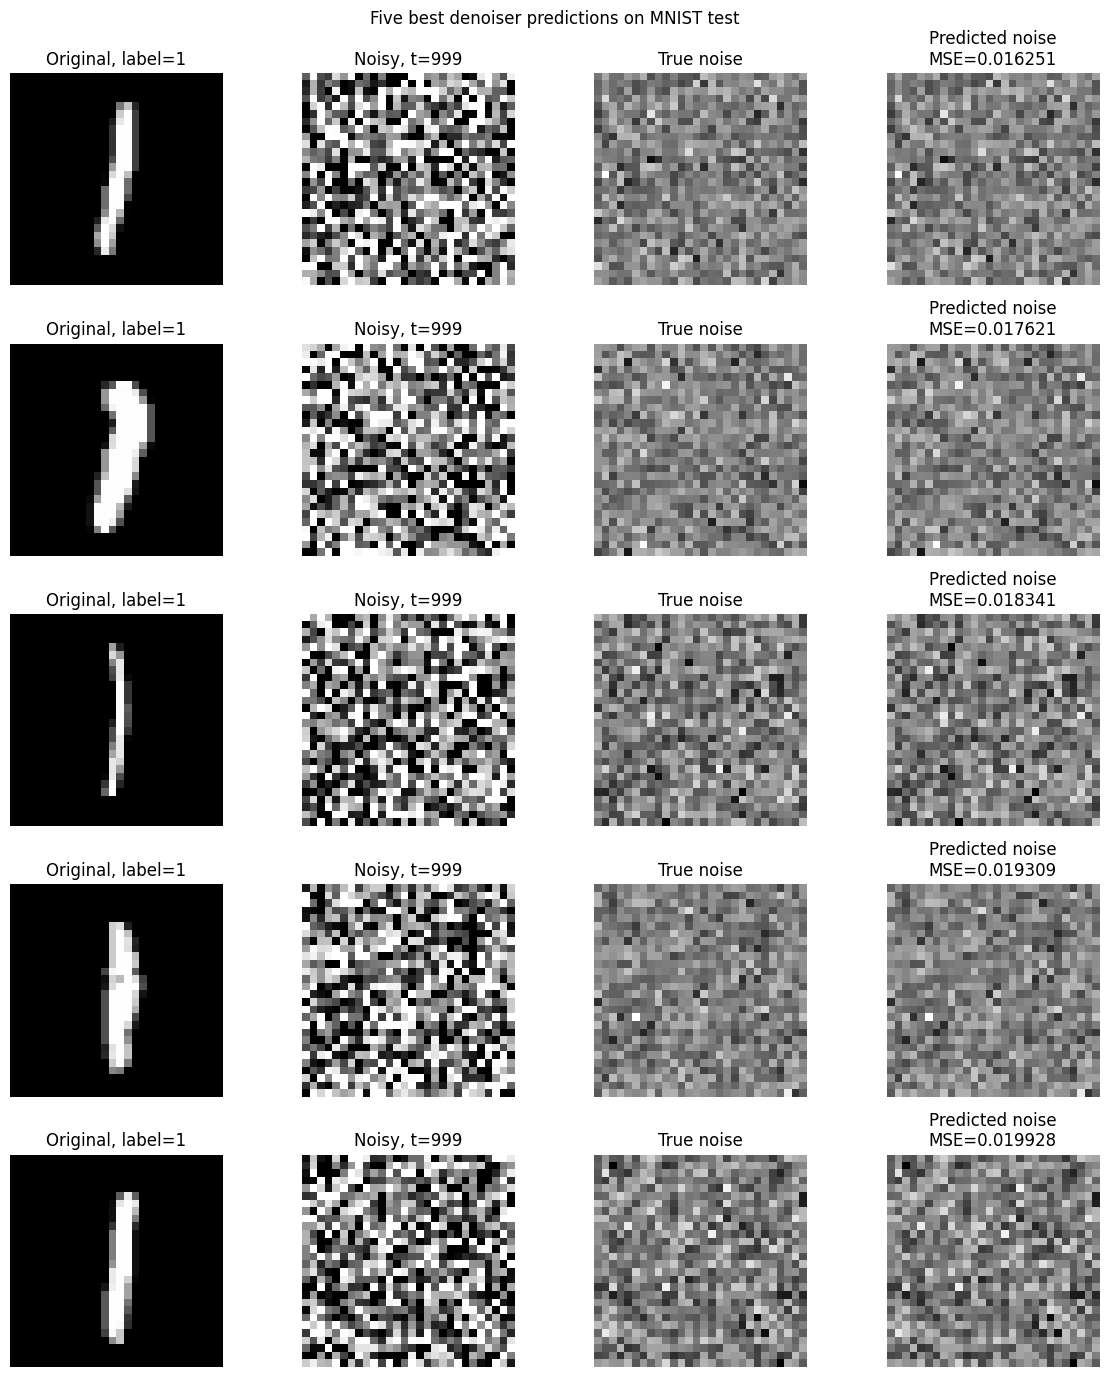

Пять лучших предсказаний denoiser:
Index= 967 | Label=1 | Mean MSE=0.016251
Index=1909 | Label=1 | Mean MSE=0.017621
Index=  40 | Label=1 | Mean MSE=0.018341
Index=1201 | Label=1 | Mean MSE=0.019309
Index=1867 | Label=1 | Mean MSE=0.019928

Средний MSE пяти лучших: 0.018290
Checkpoint: /content/drive/MyDrive/lab17/artifacts/denoiser_best_errors_full.pt
Визуализация: /content/drive/MyDrive/lab17/artifacts/denoiser_best_errors_full.png
Метрики: /content/drive/MyDrive/lab17/artifacts/task17_11_best_denoiser_predictions.json


In [15]:
# --------------------------------------------------
# Пять лучших предсказаний denoiser
# --------------------------------------------------

NUM_BEST_IMAGES = 5

best_indices = torch.topk(
    all_image_errors,
    k=NUM_BEST_IMAGES,
    largest=False
).indices

best_errors = all_image_errors[best_indices]
best_labels = all_image_labels[best_indices]

best_original = all_original_images[best_indices]
best_noisy = all_noisy_images[best_indices]
best_true_noise = all_true_noises[best_indices]
best_predicted_noise = all_predicted_noises[best_indices]

# --------------------------------------------------
# Сохранение данных
# --------------------------------------------------
BEST_CHECKPOINT = ARTIFACTS / f'denoiser_best_errors_{MODE_NAME}.pt'

torch.save({
    'best_indices_in_test': best_indices,
    'best_errors': best_errors,
    'best_labels': best_labels,
    'original_images': best_original,
    'noisy_images': best_noisy,
    'true_noise': best_true_noise,
    'predicted_noise': best_predicted_noise,
    'timesteps': WORST_TIMESTEPS,
    'seed': WORST_SEED,
    'error_definition': 'mean conditional noise MSE over selected timesteps'
}, BEST_CHECKPOINT)

# --------------------------------------------------
# Визуализация
# --------------------------------------------------
fig, axes = plt.subplots(5, 4, figsize=(12, 14))

for i in range(NUM_BEST_IMAGES):
    original = best_original[i].squeeze().numpy()
    noisy = best_noisy[i].squeeze().numpy()
    true_noise = best_true_noise[i].squeeze().numpy()
    predicted_noise = best_predicted_noise[i].squeeze().numpy()

    axes[i, 0].imshow(original, cmap='gray', vmin=-1, vmax=1)
    axes[i, 0].set_title(
        f"Original, label={best_labels[i].item()}"
    )

    axes[i, 1].imshow(noisy, cmap='gray', vmin=-1, vmax=1)
    axes[i, 1].set_title(f'Noisy, t={WORST_TIMESTEPS[-1]}')

    noise_limit = max(
        abs(true_noise.min()),
        abs(true_noise.max()),
        abs(predicted_noise.min()),
        abs(predicted_noise.max()),
        1e-6
    )

    axes[i, 2].imshow(
        true_noise,
        cmap='gray',
        vmin=-noise_limit,
        vmax=noise_limit
    )
    axes[i, 2].set_title('True noise')

    axes[i, 3].imshow(
        predicted_noise,
        cmap='gray',
        vmin=-noise_limit,
        vmax=noise_limit
    )
    axes[i, 3].set_title(
        f'Predicted noise\nMSE={best_errors[i].item():.6f}'
    )

    for j in range(4):
        axes[i, j].axis('off')

plt.suptitle('Five best denoiser predictions on MNIST test')
plt.tight_layout()

BEST_PLOT = ARTIFACTS / f'denoiser_best_errors_{MODE_NAME}.png'
plt.savefig(BEST_PLOT, dpi=150, bbox_inches='tight')
plt.show()

# --------------------------------------------------
# Сохранение метрик
# --------------------------------------------------
best_error_metrics = {
    'status': 'completed',
    'task': 'best_denoiser_predictions',
    'fast_dev_run': FAST_DEV_RUN,
    'test_samples_evaluated': int(len(all_image_errors)),
    'timesteps': WORST_TIMESTEPS,
    'best_examples': [
        {
            'test_index': int(best_indices[i].item()),
            'true_label': int(best_labels[i].item()),
            'mean_noise_mse': float(best_errors[i].item())
        }
        for i in range(NUM_BEST_IMAGES)
    ],
    'mean_best_mse': float(best_errors.mean()),
    'checkpoint': str(BEST_CHECKPOINT),
    'visualization': str(BEST_PLOT)
}

save_json('task17_11_best_denoiser_predictions.json', best_error_metrics)

# --------------------------------------------------
# Вывод фактических значений
# --------------------------------------------------
print('Пять лучших предсказаний denoiser:')

for item in best_error_metrics['best_examples']:
    print(
        f"Index={item['test_index']:4d} | "
        f"Label={item['true_label']} | "
        f"Mean MSE={item['mean_noise_mse']:.6f}"
    )

print(f"\nСредний MSE пяти лучших: {best_error_metrics['mean_best_mse']:.6f}")
print(f'Checkpoint: {BEST_CHECKPOINT}')
print(f'Визуализация: {BEST_PLOT}')
print(f'Метрики: {ARTIFACTS / "task17_11_best_denoiser_predictions.json"}')

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

**Гипотеза.** Увеличение вероятности CFG dropout с 10% до 20% увеличивает количество обучающих примеров, в которых модель не получает информацию о классе. Предполагается, что это может улучшить безусловное предсказание шума, но одновременно ослабить условное предсказание.

In [17]:
# ============================================================
# Controlled ablation — CFG dropout 10% vs 20%
# ============================================================

# ------------------------------------------------------------
# 1. Experimental configuration
# ------------------------------------------------------------

BASELINE_DROPOUT = 0.10
ABLATION_DROPOUT = 0.20

# Используем тот же бюджет optimizer steps, что и в основном задании.
ABLATION_STEPS = TRAIN_STEPS

ABLATION_SEED = SEED
VALIDATION_SIZE = 2_000
VALIDATION_TIMESTEPS = [0, 100, 250, 500, 750, 999]

# Первые 18 000 изображений — обучение,
# последние 2 000 — отдельная validation-выборка.
ablation_train_indices = list(range(18_000))
ablation_val_indices = list(range(18_000, 20_000))

ablation_train_dataset = Subset(
    mnist_train_full,
    ablation_train_indices
)

ablation_val_dataset = Subset(
    mnist_train_full,
    ablation_val_indices
)

# Отдельный генератор обеспечивает одинаковый порядок
# обучающих примеров в обоих экспериментах.
def make_ablation_train_loader():
    generator = torch.Generator()
    generator.manual_seed(ABLATION_SEED)

    return DataLoader(
        ablation_train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE == 'cuda'),
        drop_last=True,
        generator=generator
    )

ablation_val_loader = DataLoader(
    ablation_val_dataset,
    batch_size=128,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE == 'cuda')
)

# ------------------------------------------------------------
# 2. Fixed validation noise
# ------------------------------------------------------------

# Фиксируем шум для всех изображений и временных шагов.
# Обе модели оцениваются на одних и тех же входах.
validation_noise_generator = torch.Generator(device='cpu')
validation_noise_generator.manual_seed(ABLATION_SEED + 900)

validation_images = []
validation_labels = []

for images, labels in ablation_val_loader:
    validation_images.append(images)
    validation_labels.append(labels)

validation_images = torch.cat(validation_images, dim=0)
validation_labels = torch.cat(validation_labels, dim=0)

validation_noise = torch.randn(
    validation_images.shape,
    generator=validation_noise_generator
)

assert len(validation_images) == VALIDATION_SIZE

# ------------------------------------------------------------
# 3. Training function
# ------------------------------------------------------------

def train_ablation_model(dropout_probability, experiment_name):
    """
    Обучает модель с заданной вероятностью CFG dropout.

    При каждом вызове:
    - одинаковая инициализация модели;
    - одинаковый порядок обучающих изображений;
    - одинаковые случайные последовательности;
    - одинаковое число optimizer steps.
    """

    # Восстанавливаем одинаковое начальное состояние RNG.
    random.seed(ABLATION_SEED)
    np.random.seed(ABLATION_SEED)
    torch.manual_seed(ABLATION_SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(ABLATION_SEED)

    model = TinyDenoiser().to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=2e-4
    )

    loader = make_ablation_train_loader()
    data_iterator = iter(loader)

    loss_history = []
    model.train()

    start_time = time.time()

    for step in range(ABLATION_STEPS):
        try:
            images, labels = next(data_iterator)
        except StopIteration:
            data_iterator = iter(loader)
            images, labels = next(data_iterator)

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        batch_size = images.shape[0]

        # Случайный timestep для каждого изображения.
        t = torch.randint(
            low=0,
            high=T,
            size=(batch_size,),
            device=DEVICE
        )

        # Генерируем шум и получаем зашумлённые изображения.
        noise = torch.randn_like(images)
        noisy_images = q_sample(
            images,
            t,
            noise=noise,
            schedule=SCHEDULE
        )

        # CFG dropout: часть меток заменяем на null-класс 10.
        dropout_mask = (
            torch.rand(batch_size, device=DEVICE)
            < dropout_probability
        )

        training_labels = labels.clone()
        training_labels[dropout_mask] = 10

        predicted_noise = model(
            noisy_images,
            t,
            training_labels
        )

        loss = F.mse_loss(predicted_noise, noise)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )
        optimizer.step()

        loss_history.append(loss.item())

        if (step + 1) % 100 == 0 or step == 0:
            print(
                f"{experiment_name}: "
                f"step {step + 1}/{ABLATION_STEPS}, "
                f"loss={loss.item():.5f}"
            )

    training_time = time.time() - start_time

    model.eval()

    checkpoint_path = (
        ARTIFACTS / f"bonus_cfg_dropout_{experiment_name}.pt"
    )

    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "dropout_probability": dropout_probability,
            "steps": ABLATION_STEPS,
            "seed": ABLATION_SEED,
            "loss_history": loss_history
        },
        checkpoint_path
    )

    return model, {
        "dropout_probability": dropout_probability,
        "training_steps": ABLATION_STEPS,
        "training_time_sec": training_time,
        "final_train_loss": float(loss_history[-1]),
        "checkpoint": str(checkpoint_path)
    }


# ------------------------------------------------------------
# 4. Validation: conditional and unconditional noise MSE
# ------------------------------------------------------------

@torch.no_grad()
def evaluate_ablation_model(model):
    model.eval()

    results = {}

    for timestep in VALIDATION_TIMESTEPS:
        conditional_squared_error = 0.0
        unconditional_squared_error = 0.0
        number_of_elements = 0

        for start in range(0, VALIDATION_SIZE, 128):
            end = min(start + 128, VALIDATION_SIZE)

            images = validation_images[start:end].to(DEVICE)
            labels = validation_labels[start:end].to(DEVICE)
            noise = validation_noise[start:end].to(DEVICE)

            batch_size = images.shape[0]

            t = torch.full(
                (batch_size,),
                timestep,
                device=DEVICE,
                dtype=torch.long
            )

            noisy_images = q_sample(
                images,
                t,
                noise=noise,
                schedule=SCHEDULE
            )

            # Условное предсказание: известна цифра.
            predicted_conditional = model(
                noisy_images,
                t,
                labels
            )

            # Безусловное предсказание: null-класс 10.
            null_labels = torch.full_like(labels, 10)

            predicted_unconditional = model(
                noisy_images,
                t,
                null_labels
            )

            conditional_squared_error += F.mse_loss(
                predicted_conditional,
                noise,
                reduction='sum'
            ).item()

            unconditional_squared_error += F.mse_loss(
                predicted_unconditional,
                noise,
                reduction='sum'
            ).item()

            number_of_elements += noise.numel()

        results[f"conditional_mse_t{timestep}"] = (
            conditional_squared_error / number_of_elements
        )

        results[f"unconditional_mse_t{timestep}"] = (
            unconditional_squared_error / number_of_elements
        )

    conditional_values = [
        results[f"conditional_mse_t{t}"]
        for t in VALIDATION_TIMESTEPS
    ]

    unconditional_values = [
        results[f"unconditional_mse_t{t}"]
        for t in VALIDATION_TIMESTEPS
    ]

    results["conditional_mse_mean"] = float(
        np.mean(conditional_values)
    )

    results["unconditional_mse_mean"] = float(
        np.mean(unconditional_values)
    )

    return results


# ------------------------------------------------------------
# 5. Run two controlled experiments
# ------------------------------------------------------------

print("Experiment A: CFG dropout = 10%")

baseline_model, baseline_info = train_ablation_model(
    BASELINE_DROPOUT,
    "baseline_10pct"
)

print("\nExperiment B: CFG dropout = 20%")

ablation_model, ablation_info = train_ablation_model(
    ABLATION_DROPOUT,
    "ablation_20pct"
)

print("\nEvaluating both models on the same validation inputs...")

baseline_metrics = evaluate_ablation_model(baseline_model)
ablation_metrics = evaluate_ablation_model(ablation_model)


# ------------------------------------------------------------
# 6. Build measurement table
# ------------------------------------------------------------

measurement_rows = []

for name, info, metrics in [
    ("Baseline: dropout 10%", baseline_info, baseline_metrics),
    ("Ablation: dropout 20%", ablation_info, ablation_metrics)
]:
    measurement_rows.append({
        "Experiment": name,
        "CFG dropout": info["dropout_probability"],
        "Training steps": info["training_steps"],
        "Training time (sec)": round(
            info["training_time_sec"], 2
        ),
        "Final train loss": info["final_train_loss"],
        "Conditional validation MSE": (
            metrics["conditional_mse_mean"]
        ),
        "Unconditional validation MSE": (
            metrics["unconditional_mse_mean"]
        )
    })

measurement_table = pd.DataFrame(measurement_rows)

print("\nBONUS EXPERIMENT: MEASUREMENTS")
display(
    measurement_table.style.format({
        "CFG dropout": "{:.0%}",
        "Training time (sec)": "{:.2f}",
        "Final train loss": "{:.6f}",
        "Conditional validation MSE": "{:.6f}",
        "Unconditional validation MSE": "{:.6f}"
    })
)

# ------------------------------------------------------------
# 7. Calculate relative differences
# ------------------------------------------------------------

def relative_change(baseline, ablation):
    if baseline == 0:
        return float("nan")
    return 100.0 * (ablation - baseline) / baseline

conditional_change = relative_change(
    baseline_metrics["conditional_mse_mean"],
    ablation_metrics["conditional_mse_mean"]
)

unconditional_change = relative_change(
    baseline_metrics["unconditional_mse_mean"],
    ablation_metrics["unconditional_mse_mean"]
)

print("\nRelative change (20% compared with 10%):")
print(f"Conditional MSE:   {conditional_change:+.2f}%")
print(f"Unconditional MSE: {unconditional_change:+.2f}%")

# ------------------------------------------------------------
# 8. Save all measurements and experiment configuration
# ------------------------------------------------------------

bonus_results = {
    "hypothesis": (
        "Increasing CFG dropout from 10% to 20% may improve "
        "unconditional noise prediction, but may weaken "
        "conditional noise prediction."
    ),
    "configuration": {
        "baseline_dropout": BASELINE_DROPOUT,
        "ablation_dropout": ABLATION_DROPOUT,
        "seed": ABLATION_SEED,
        "training_steps": ABLATION_STEPS,
        "training_images": len(ablation_train_dataset),
        "validation_images": len(ablation_val_dataset),
        "validation_timesteps": VALIDATION_TIMESTEPS,
        "test_set_used_for_selection": False
    },
    "baseline": {
        **baseline_info,
        **baseline_metrics
    },
    "ablation": {
        **ablation_info,
        **ablation_metrics
    },
    "relative_change_percent": {
        "conditional_mse": conditional_change,
        "unconditional_mse": unconditional_change
    }
}

save_json(
    "task17_bonus_cfg_dropout_ablation.json",
    bonus_results
)

measurement_table.to_csv(
    ARTIFACTS / "task17_bonus_cfg_dropout_table.csv",
    index=False
)

print("\nSaved:")
print(ARTIFACTS / "task17_bonus_cfg_dropout_ablation.json")
print(ARTIFACTS / "task17_bonus_cfg_dropout_table.csv")
print(ARTIFACTS / "bonus_cfg_dropout_baseline_10pct.pt")
print(ARTIFACTS / "bonus_cfg_dropout_ablation_20pct.pt")

Experiment A: CFG dropout = 10%
baseline_10pct: step 1/10000, loss=0.90925
baseline_10pct: step 100/10000, loss=0.06123
baseline_10pct: step 200/10000, loss=0.05455
baseline_10pct: step 300/10000, loss=0.05072
baseline_10pct: step 400/10000, loss=0.03762
baseline_10pct: step 500/10000, loss=0.04364
baseline_10pct: step 600/10000, loss=0.03632
baseline_10pct: step 700/10000, loss=0.03015
baseline_10pct: step 800/10000, loss=0.03263
baseline_10pct: step 900/10000, loss=0.02969
baseline_10pct: step 1000/10000, loss=0.02796
baseline_10pct: step 1100/10000, loss=0.03235
baseline_10pct: step 1200/10000, loss=0.02739
baseline_10pct: step 1300/10000, loss=0.03042
baseline_10pct: step 1400/10000, loss=0.02999
baseline_10pct: step 1500/10000, loss=0.03572
baseline_10pct: step 1600/10000, loss=0.02620
baseline_10pct: step 1700/10000, loss=0.03178
baseline_10pct: step 1800/10000, loss=0.02784
baseline_10pct: step 1900/10000, loss=0.02773
baseline_10pct: step 2000/10000, loss=0.02774
baseline_10pct

,Experiment,CFG dropout,Training steps,Training time (sec),Final train loss,Conditional validation MSE,Unconditional validation MSE
0,Baseline: dropout 10%,10%,10000,669.60,0.031226,0.048743,0.049279
1,Ablation: dropout 20%,20%,10000,681.92,0.031599,0.048462,0.049081



Relative change (20% compared with 10%):
Conditional MSE:   -0.58%
Unconditional MSE: -0.40%

Saved:
/content/drive/MyDrive/lab17/artifacts/task17_bonus_cfg_dropout_ablation.json
/content/drive/MyDrive/lab17/artifacts/task17_bonus_cfg_dropout_table.csv
/content/drive/MyDrive/lab17/artifacts/bonus_cfg_dropout_baseline_10pct.pt
/content/drive/MyDrive/lab17/artifacts/bonus_cfg_dropout_ablation_20pct.pt


## Анализ результатов

Независимый классификатор показал точность 97.85% на тестовой выборке MNIST при значении loss 0.054401. Это говорит о том, что классификатор хорошо распознаёт реальные цифры, поэтому его можно использовать для проверки результатов генерации.

При сравнении разных значений CFG видно, что увеличение guidance scale улучшает генерацию цифр. При CFG = 0 точность составила 11.6%, при CFG = 1 — 23.7%, при CFG = 3 — 43.2%, а при **CFG = 5 достигла 52.3%**. Значит, classifier-free guidance помогает модели лучше следовать заданному классу. Однако результат всё ещё заметно хуже, чем на реальных изображениях.

Для CFG = 5 качество генерации сильно различается между цифрами. **Лучше всего распознавались 8 (81%), 2 и 3 (по 78%), а хуже всего — 9 (3%), 6 (27%) и 7 (30%).** Вероятно, некоторые цифры модели пока сложнее воспроизводить правильно.

При анализе ошибки предсказания шума заметно, что MSE уменьшается с увеличением временного шага. **На шагах от 50 до 500 условное предсказание немного точнее безусловного.** На последних шагах разница почти исчезает.

В дополнительном эксперименте я сравнил CFG dropout 10% и 20%. **При увеличении dropout conditional MSE уменьшилась на 0.58%, а unconditional MSE — на 0.40%.** То есть немного улучшились оба показателя. Предположение о том, что улучшение безусловного предсказания приведёт к ухудшению условного, не подтвердилось. При этом разница очень небольшая, поэтому нельзя уверенно утверждать, что dropout 20% лучше.

В целом эксперименты показали, что увеличение CFG scale помогает генерировать цифры, более соответствующие заданным классам. При этом качество генерации пока зависит от конкретной цифры, а до качества распознавания реальных изображений модели ещё далеко. Для улучшения результата можно увеличить время обучения и использовать более сложную архитектуру.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.